# 02. 环境 GWAS

分析非洲高粱地方品种基因型与 31 个环境变量的关联，使用 MAGMA 将位点关联汇总至基因层面，并结合开花时间及 cis-eQTL 注释检查是否捕捉到局域适应信号。


### 环境设置


In [96]:
import warnings
warnings.filterwarnings('ignore')

import os
import socket
import sys
from datetime import datetime
from time import perf_counter
import pandas as pd
import yaml

%load_ext autoreload
%autoreload 2

with open('config/project.yaml') as handle:
    project_config = yaml.safe_load(handle)
project_dir = project_config['remote']['project_root']
if os.path.realpath(os.getcwd()) != os.path.realpath(project_dir):
    raise ValueError(f'Working directory {os.getcwd()} must match configured project root {project_dir}.')
data_dir = f'{project_dir}/data'
source_dir = f'{data_dir}/source'
results_dir = f'{data_dir}/results'
os.makedirs(results_dir, exist_ok=True)
if project_dir not in sys.path:
    sys.path.insert(0, project_dir)

from src.plot import set_plot_style
set_plot_style()

print(f'Host: {socket.gethostname()}')
print(f'Working directory: {os.getcwd()}')
print(f'Python: {sys.executable}')
print(f"Environment prefix: {os.environ.get('CONDA_PREFIX', '<not set>')}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Host: rock01.local
Working directory: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum
Python: /lustre/home/dobby/Program/agent_program/micromamba-root/envs/dobby-base/bin/python
Environment prefix: /lustre/home/dobby/Program/agent_program/micromamba-root/envs/dobby-base


## 1. 非洲高粱地方品种的群体与环境


### 地方品种元数据

样本信息、植物学分组、采集地点及环境变量用于描述地方品种群体及其所处环境。


In [75]:
landrace_metadata_csv = f'{source_dir}/landraces_metadata.csv'
landrace_metadata_df = pd.read_csv(landrace_metadata_csv)
landrace_metadata_df

,ISnum,PInumber,LIB,Sample,WASAP,PlantName,Germplasm,BotanicalType,Latitude,Longitude,...,bio17,bio19,alt,NTO,CLYPPT,annualPET,TPH,topoWet,PlotBotanicalType,min_dist_to_striga
0,NaN,NaN,IZII,Ni205_177,Ni205,NaN,Landrace,Durra-caudatum,13.232833,8.229278,...,0,0,460.0,373.0,6.0,2017.839966,93.0,13.02,Durra-caudatum,62.236593
1,NaN,NaN,IZIY,Ni295_302,Ni295,El Dan Mato,Landrace,Durra-caudatum,13.123722,7.008417,...,0,0,411.0,368.0,8.0,1994.109985,122.0,12.96,Durra-caudatum,22.765923
2,NaN,NaN,IZIX,Ni293_172,Ni293,Ja Dawa,Landrace,Durra-caudatum,13.024194,7.046028,...,0,0,431.0,412.0,9.0,1982.750000,107.0,12.64,Durra-caudatum,23.155054
3,NaN,NaN,IZJH,Sen053_041,Sn053,Diériker Ndélé,Landrace,Guinea,15.786164,-16.523998,...,7,46,8.0,626.0,18.0,1601.599976,231.0,13.84,Guinea,25.733178
4,NaN,NaN,IZIP,Ni224_310,Ni224,Ja Dawa,Landrace,Durra-caudatum,13.247722,7.736417,...,0,0,428.0,424.0,9.0,1997.520020,96.0,12.95,Durra-caudatum,57.367592
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438,IS9524,PI563289,IZKC,PI563289,NaN,IS9524,Cultivated,Kafir-durra,-25.746111,28.188056,...,173,256,1335.0,1121.0,27.0,1541.000000,764.0,11.27,Kafir-durra,1131.597982
439,IS9883,PI571271,IPEJ,PI571271,NaN,IS9883,Landrace,Caudatum,11.189999,24.149999,...,0,0,559.0,551.0,36.0,2213.679932,120.0,14.38,Caudatum,198.525796
440,IS9885,PI571273,IXPG,PI571273,NaN,IS9885,Landrace,Caudatum,6.480000,29.420000,...,135,5469,479.0,665.0,27.0,1959.829956,245.0,13.51,Caudatum,209.075913
441,IS9911,PI571292,IPEK,PI571292,NaN,IS9911,Landrace,Caudatum,11.016667,29.716667,...,2,4130,513.0,744.0,40.0,2091.260010,276.0,12.11,Caudatum,1.068439


### 1.1 群体分布与亲缘关系



#### 1.1.1 地理分布


展示位于非洲大陆的高粱地方品种的地理分布，以颜色区分植物学分组。


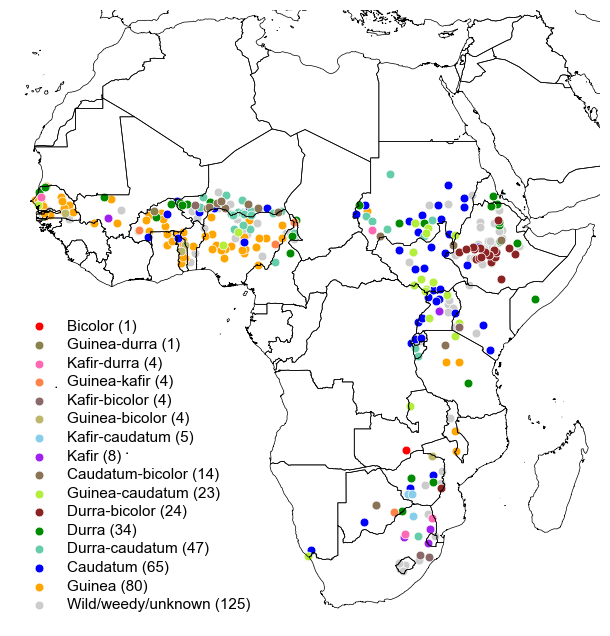

Mapped samples: 443 / 443
Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_botanical_map.figS1.pdf


In [76]:
from src.env_vars import landraces_botanical_map_plotter

world_map_shp = f'{source_dir}/natural_earth/ne_10m_admin_0_countries/ne_10m_admin_0_countries.shp'
save_fig_path = f'{results_dir}/landraces_botanical_map.figS1.pdf'
longitude_limit = (-20, 52)
latitude_limit = (-37, 38)

botanical_map_df = landraces_botanical_map_plotter(
    landrace_metadata_df, save_fig_path, world_map_shp,
    longitude_limit=longitude_limit, latitude_limit=latitude_limit, figsize=(8, 8),
)
print(f'Mapped samples: {len(botanical_map_df):,} / {len(landrace_metadata_df):,}')
print(f'Figure: {save_fig_path}')


**图 1. 本研究所分析的高粱地方品种的地理来源，颜色表示植物学类型。**


#### 1.1.2 亲缘关系



- LD-pruned SNP 集合

使用填补后的地方品种基因型，基于plink进行MAF过滤和LD修剪.


In [77]:
from src.kinship import prune_snps_with_plink

landraces_vcf_file = f'{results_dir}/landraces.vcf.gz'
min_maf = 0.01
ld_window_kb = 15
ld_step = 50
r2_threshold = 0.5
kinship_threads = project_config['resources']['interactive']['cores']
kinship_memory_mb = 16000
kinship_tag = f'landraces.snp_pruned.maf{min_maf}.win{ld_window_kb}kb.step{ld_step}.r2{r2_threshold}'
kinship_result_prefix = f'{results_dir}/{kinship_tag}'
snp_pruned_vcf_file = f'{kinship_result_prefix}.vcf.gz'
ibs_distance_file = f'{kinship_result_prefix}.ibs.mdist'
ibs_distance_id_file = f'{ibs_distance_file}.id'
kinship_file = f'{kinship_result_prefix}.grm_cov.rel'
kinship_id_file = f'{kinship_file}.id'
nj_tree_prefix = f'{kinship_result_prefix}.ibs'
nj_tree_file = f'{nj_tree_prefix}.nj.tree'
pruned_result_files = [f'{kinship_result_prefix}.{suffix}' for suffix in
                       ('bed', 'bim', 'fam', 'prune.in', 'prune.out', 'vcf.gz', 'vcf.gz.tbi')]

stage_start = perf_counter()
pruned_recomputed = not all(os.path.exists(path) for path in pruned_result_files)
if not pruned_recomputed:
    print(f'[{datetime.now():%H:%M:%S}] Reusing PLINK SNP panel: {kinship_result_prefix}', flush=True)
else:
    prune_snps_with_plink(
        landraces_vcf_file, kinship_result_prefix, min_maf=min_maf,
        ld_window_kb=ld_window_kb, ld_step=ld_step, r2_threshold=r2_threshold,
        threads=kinship_threads, memory_mb=kinship_memory_mb,
    )
if not all(os.path.exists(path) for path in pruned_result_files):
    raise RuntimeError('PLINK SNP panel or indexed VCF is incomplete.')
pruned_sample_ids = pd.read_csv(f'{kinship_result_prefix}.fam', sep=r'\s+', header=None, dtype=str)[1].tolist()
pruned_snp_count = len(pd.read_csv(f'{kinship_result_prefix}.bim', sep=r'\s+', header=None))
print(f'Pruned SNPs: {pruned_snp_count:,}; samples: {len(pruned_sample_ids):,}')
print(f'[{datetime.now():%H:%M:%S}] SNP panel ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[23:48:44] Reusing PLINK SNP panel: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces.snp_pruned.maf0.01.win15kb.step50.r20.5


Pruned SNPs: 3,055,388; samples: 443
[23:48:46] SNP panel ready (2.2 s)


- 遗传距离与协方差亲缘矩阵

使用 PLINK 计算用于IBS 遗传距离和用于 GEMMA 的 SNP 协方差矩阵。


In [78]:
from src.kinship import calculate_plink_kinship
from src.vcf import get_sample_list_from_vcf

matrix_result_files = [ibs_distance_file, ibs_distance_id_file, kinship_file, kinship_id_file]
stage_start = perf_counter()
matrices_recomputed = pruned_recomputed or not all(os.path.exists(path) for path in matrix_result_files)
if not matrices_recomputed:
    print(f'[{datetime.now():%H:%M:%S}] Reusing PLINK distance and covariance: {kinship_result_prefix}', flush=True)
else:
    calculate_plink_kinship(kinship_result_prefix, threads=kinship_threads, memory_mb=kinship_memory_mb)
if not all(os.path.exists(path) for path in matrix_result_files):
    raise RuntimeError('PLINK distance or kinship matrix is incomplete.')
for id_file in (ibs_distance_id_file, kinship_id_file):
    matrix_sample_ids = pd.read_csv(id_file, sep=r'\s+', header=None, dtype=str)[1].tolist()
    if matrix_sample_ids != pruned_sample_ids:
        raise ValueError('PLINK matrix and SNP-panel sample orders differ.')
if pruned_sample_ids != get_sample_list_from_vcf(snp_pruned_vcf_file):
    raise ValueError('Pruned VCF and PLINK matrix sample orders differ.')
print(f'IBS distance: {ibs_distance_file}')
print(f'GEMMA kinship: {kinship_file}')
print(f'[{datetime.now():%H:%M:%S}] Matrices ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[23:48:46] Reusing PLINK distance and covariance: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces.snp_pruned.maf0.01.win15kb.step50.r20.5
IBS distance: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces.snp_pruned.maf0.01.win15kb.step50.r20.5.ibs.mdist
GEMMA kinship: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces.snp_pruned.maf0.01.win15kb.step50.r20.5.grm_cov.rel
[23:48:47] Matrices ready (0.4 s)


- 推断地方品种间的遗传关系

使用 FastME，基于 PLINK IBS 遗传距离构建邻接树。


In [79]:
from src.kinship import build_nj_tree

stage_start = perf_counter()
if not matrices_recomputed and all(os.path.exists(path) for path in (f'{nj_tree_prefix}.phylip', nj_tree_file)):
    print(f'[{datetime.now():%H:%M:%S}] Reusing NJ tree: {nj_tree_file}', flush=True)
else:
    build_nj_tree(ibs_distance_file, ibs_distance_id_file, nj_tree_prefix, threads=kinship_threads)
if not os.path.exists(nj_tree_file):
    raise RuntimeError('NJ tree is incomplete.')
print(f'[{datetime.now():%H:%M:%S}] NJ tree ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[23:48:47] Reusing NJ tree: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces.snp_pruned.maf0.01.win15kb.step50.r20.5.ibs.nj.tree
[23:48:47] NJ tree ready (0.0 s)


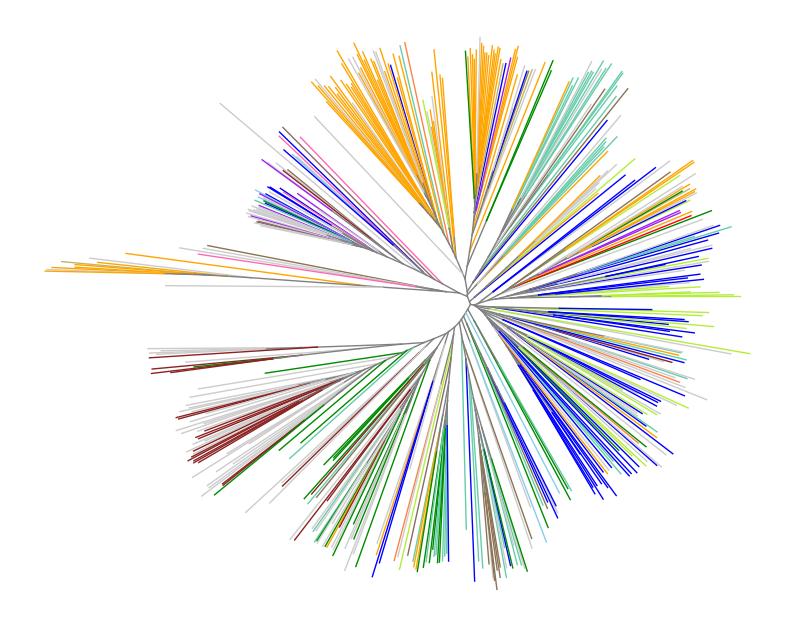

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_nj_tree.figS1.pdf


In [80]:
from src.env_vars import nj_tree_plotter

save_fig_path = f'{results_dir}/landraces_nj_tree.figS1.pdf'
nj_tree_plotter(nj_tree_file, landrace_metadata_df, save_fig_path=save_fig_path, figsize=(10, 10))
print(f'Figure: {save_fig_path}')


**图 2. 基于 LD-pruned SNP 构建的邻接树。**


### 1.2 群体基因组特征

描述地方品种群体的连锁不平衡，以及基因组注释和遗传变异沿染色体的分布。


#### 1.2.1 连锁不平衡

连锁不平衡（LD）随物理距离的衰减

统计至最远20 kb

In [81]:
from src.ld import calculate_ld_decay

landraces_qc_vcf_file = f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz'
landraces_qc_stat_h5 = f'{landraces_qc_vcf_file}.var_stat.h5'
ld_max_distance = 20000
ld_bin_size = 50
ld_pool_num = 20
ld_force_recompute = False
ld_tag = f'{landraces_qc_vcf_file}.ld_decay'
ld_decay_cache = f'{ld_tag}.csv.gz'
ld_figure_file = f'{ld_tag}.pdf'
ld_half_dist_csv = f'{ld_tag}.threshold_distances.csv.gz'

stage_start = perf_counter()
if not ld_force_recompute and os.path.exists(ld_decay_cache):
    print(f'[{datetime.now():%H:%M:%S}] Reusing LD decay statistics: {ld_decay_cache}', flush=True)
    ld_decay_df = pd.read_csv(ld_decay_cache)
else:
    print(f'[{datetime.now():%H:%M:%S}] Calculating LD decay with {ld_pool_num} workers', flush=True)
    with pd.HDFStore(landraces_qc_stat_h5, mode='r') as ld_store:
        ld_sites = pd.concat([ld_store[key] for key in ld_store.keys()], ignore_index=True)
    ld_sites = ld_sites.sort_values(['CHROM', 'POS']).reset_index(drop=True)
    ld_decay_df = calculate_ld_decay(
        ld_sites, landraces_qc_vcf_file, max_decay_size=ld_max_distance,
        curve_bin_size=ld_bin_size, pool_num=ld_pool_num,
    )
    temporary_csv = f'{ld_decay_cache}.tmp'
    ld_decay_df.to_csv(temporary_csv, index=False, compression='gzip')
    os.replace(temporary_csv, ld_decay_cache)
print(f'[{datetime.now():%H:%M:%S}] LD decay statistics ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[23:48:52] Reusing LD decay statistics: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.vcf.gz.ld_decay.csv.gz
[23:48:52] LD decay statistics ready (0.0 s)


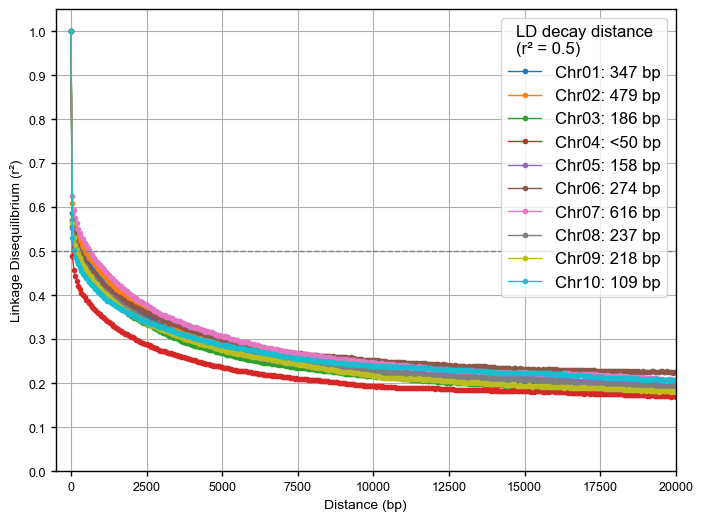

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.vcf.gz.ld_decay.pdf
Figure data: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.vcf.gz.ld_decay.csv.gz


,CHROM,half_ld_value,half_ld_dist,status
0,Chr01,0.5,347.529496,reached
1,Chr02,0.5,479.221340,reached
2,Chr03,0.5,186.479450,reached
3,Chr04,0.5,NaN,below_in_first_bin
4,Chr05,0.5,158.289722,reached
5,Chr06,0.5,274.244747,reached
6,Chr07,0.5,616.334547,reached
7,Chr08,0.5,237.270528,reached
8,Chr09,0.5,218.100606,reached
9,Chr10,0.5,109.921828,reached


In [82]:
import matplotlib.pyplot as plt
from src.ld import plot_ld_decay

ld_half_value = 0.5
ld_decay_df = pd.read_csv(ld_decay_cache)
ld_fig, ld_ax, ld_half_dist_df = plot_ld_decay(
    ld_decay_df, half_ld_value=ld_half_value, figsize=(8, 6),
    xlim=(-500, ld_max_distance), save_fig_path=ld_figure_file,
)
ld_half_dist_df.to_csv(ld_half_dist_csv, index=False, compression='gzip')
plt.show()
print(f'Figure: {ld_figure_file}')
print(f'Figure data: {ld_decay_cache}')
ld_half_dist_df


**图 3. 高粱地方品种的连锁不平衡衰减。**


将分析扩展至更远距离，观察更大尺度上的 LD 特征 (最远至 50 Mb)

In [83]:
from src.ld import calculate_multiscale_ld_decay

landraces_qc_vcf_file = f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz'
landraces_qc_stat_h5 = f'{landraces_qc_vcf_file}.var_stat.h5'
multiscale_ld_csv = f'{landraces_qc_vcf_file}.multiscale_ld_decay.csv.gz'
multiscale_ld_pdf = f'{landraces_qc_vcf_file}.multiscale_ld_decay.pdf'
multiscale_ld_workers = 20

stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Preparing multiscale LD statistics with {multiscale_ld_workers} workers', flush=True)
multiscale_ld_df = calculate_multiscale_ld_decay(
    landraces_qc_stat_h5, landraces_qc_vcf_file, full_distance=200_000,
    max_pairs_per_bin=50_000, random_seed=42,
    pool_num=multiscale_ld_workers, cache_file=multiscale_ld_csv,
)
print(f'[{datetime.now():%H:%M:%S}] Multiscale LD statistics ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[23:48:54] Preparing multiscale LD statistics with 20 workers
Reading existing multiscale LD CSV: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.vcf.gz.multiscale_ld_decay.csv.gz
[23:48:54] Multiscale LD statistics ready (0.0 s)


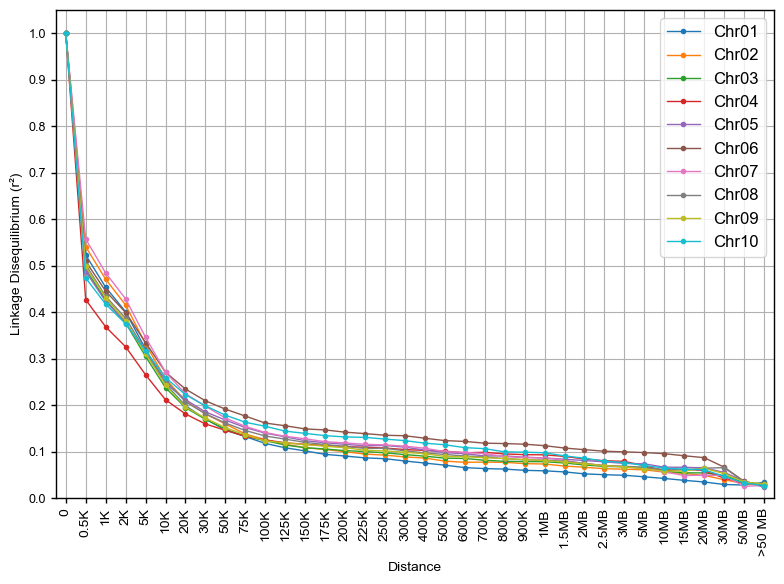

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.vcf.gz.multiscale_ld_decay.pdf
Figure data: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.vcf.gz.multiscale_ld_decay.csv.gz


In [84]:
import matplotlib.pyplot as plt
from src.ld import plot_multiscale_ld_decay

multiscale_ld_df = pd.read_csv(multiscale_ld_csv)
multiscale_ld_fig, multiscale_ld_ax = plot_multiscale_ld_decay(
    multiscale_ld_df, save_fig_path=multiscale_ld_pdf, figsize=(8, 6),
)
plt.show()
print(f'Figure: {multiscale_ld_pdf}')
print(f'Figure data: {multiscale_ld_csv}')


**图 4. 高粱地方品种的连锁不平衡衰减（最远至 50 Mb）。**


- 识别单倍型区块

通过 PLINK 识别单倍型区块。区块长度描述局部连锁变异的延伸范围，与 LD 衰减曲线相互补充。


In [85]:
import subprocess

landraces_qc_vcf_file = f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz'
plink_blocks_dir = f'{results_dir}/landraces_qc_maf0.05_het0.05.plink_blocks'
plink_force_recompute = False
plink_maf = 0.05
plink_max_kb = 500
plink_threads = 20
plink_parallel = 4
plink_block_memory_mb = 64000
plink_preprocess_memory_mb = 16000
plink_blocks_prefix = f'{plink_blocks_dir}/landraces.maf{plink_maf}.biallelic.blocks_max{plink_max_kb}kb'
plink_blocks_result_file = f'{plink_blocks_prefix}.project_chr.blocks.det'

stage_start = perf_counter()
reuse_blocks = os.path.exists(plink_blocks_result_file) and not plink_force_recompute
if reuse_blocks:
    print(f'[{datetime.now():%H:%M:%S}] Reusing PLINK blocks: {plink_blocks_result_file}', flush=True)
else:
    print(f'[{datetime.now():%H:%M:%S}] Calculating PLINK blocks', flush=True)
    subprocess.run([
        'bash', f'{project_dir}/src/plink_block.sh',
        '--vcf', landraces_qc_vcf_file, '--out-dir', plink_blocks_dir,
        '--prefix', 'landraces', '--maf', str(plink_maf),
        '--max-kb', str(plink_max_kb), '--threads', str(plink_threads),
        '--parallel', str(plink_parallel),
        '--block-memory-mb', str(plink_block_memory_mb),
        '--preprocess-memory-mb', str(plink_preprocess_memory_mb),
    ], check=True)
ld_blocks = pd.read_csv(plink_blocks_result_file, sep=r'\s+')
print(f'[{datetime.now():%H:%M:%S}] PLINK blocks ready ({perf_counter() - stage_start:.1f} s)', flush=True)
print(f'Blocks: {len(ld_blocks):,}')
ld_blocks.groupby('CHR').size().rename('BLOCK_COUNT').to_frame()


[23:48:56] Reusing PLINK blocks: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.plink_blocks/landraces.maf0.05.biallelic.blocks_max500kb.project_chr.blocks.det
[23:48:57] PLINK blocks ready (1.2 s)
Blocks: 133,207


,BLOCK_COUNT
CHR,
Chr01,16766
Chr02,15428
Chr03,16549
Chr04,13845
Chr05,15528
Chr06,11476
Chr07,11438
Chr08,10737
Chr09,10940


单倍型区块长度分布

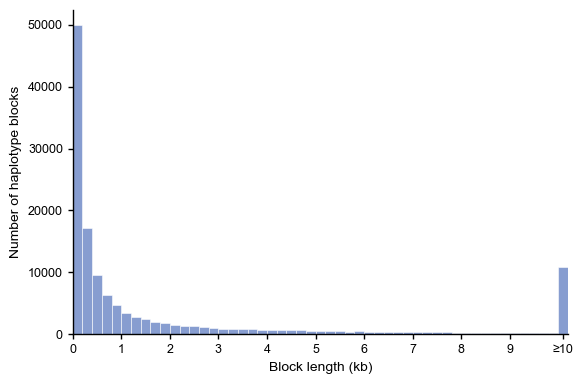

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.plink_blocks/landraces.maf0.05.biallelic.blocks_max500kb.length_distribution.pdf
Plot data: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_maf0.05_het0.05.plink_blocks/landraces.maf0.05.biallelic.blocks_max500kb.length_distribution.csv.gz


In [86]:
import numpy as np
import matplotlib.pyplot as plt

block_lengths_df = pd.read_csv(plink_blocks_result_file, sep=r'\s+', usecols=['KB'])
block_lengths_kb = block_lengths_df['KB'].to_numpy()
block_length_plot_prefix = f'{plink_blocks_prefix}.length_distribution'
block_length_cutoff_kb = 10
block_length_bin_kb = 0.2

bin_edges = np.linspace(0, block_length_cutoff_kb, round(block_length_cutoff_kb / block_length_bin_kb) + 1)
block_counts, _ = np.histogram(block_lengths_kb[block_lengths_kb < block_length_cutoff_kb], bins=bin_edges)
block_length_plot_df = pd.DataFrame({
    'LEFT_KB': bin_edges,
    'RIGHT_KB': np.r_[bin_edges[1:], np.inf],
    'BLOCK_COUNT': np.r_[block_counts, (block_lengths_kb >= block_length_cutoff_kb).sum()],
    'BIN_LABEL': [f'{left:g}–{right:g}' for left, right in zip(bin_edges[:-1], bin_edges[1:])]
                 + [f'≥{block_length_cutoff_kb:g}'],
})

block_length_fig, block_length_ax = plt.subplots(figsize=(6, 4))
block_length_ax.bar(
    block_length_plot_df['LEFT_KB'] + block_length_bin_kb / 2,
    block_length_plot_df['BLOCK_COUNT'], width=block_length_bin_kb,
    color='#879DD0', edgecolor='white', linewidth=0.4,
)
block_length_ax.set_xlabel('Block length (kb)')
block_length_ax.set_ylabel('Number of haplotype blocks')
block_length_ax.set_xlim(0, block_length_cutoff_kb + block_length_bin_kb)
block_length_ax.set_xticks(
    [*range(block_length_cutoff_kb), block_length_cutoff_kb + block_length_bin_kb / 2],
    [*map(str, range(block_length_cutoff_kb)), f'≥{block_length_cutoff_kb}'],
)
block_length_ax.spines[['top', 'right']].set_visible(False)
block_length_fig.tight_layout()
block_length_plot_df.to_csv(f'{block_length_plot_prefix}.csv.gz', index=False, compression='gzip')
block_length_fig.savefig(f'{block_length_plot_prefix}.pdf', bbox_inches='tight')
block_length_fig.savefig(f'{block_length_plot_prefix}.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Figure: {block_length_plot_prefix}.pdf')
print(f'Plot data: {block_length_plot_prefix}.csv.gz')


**图 5. 高粱地方品种基因组中单倍型区块长度的分布。**


#### 1.2.2 基因组特征沿染色体的分布

描述基因组功能区域、单倍型区块长度、核苷酸多样性和重组率沿染色体的分布。以 500 bp 窗口计算局部统计，再汇总至 1 Mb 展示。


以 500 bp 窗口统计

In [87]:
from src.contexts import (
    get_genome_windows_contexts, get_genome_window_statistics, save_context_table,
)

landraces_vcf_file = f'{results_dir}/landraces.vcf.gz'
genome_fasta_file = f'{source_dir}/Sbicolor_730_v5.0.fa.gz'
gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
repeat_gff_file = f'{source_dir}/Sbicolor_730_v5.1.repeatmasked_assembly_v5.0.gff3.gz'
recombination_file = f'{source_dir}/avg_cM_genomewide_NAM_population.csv.gz'
bed_files = {name: f'{source_dir}/{name}s.v5.bed.gz' for name in ['ACR', 'UMR']}
window_size = 500
min_variant_count = 3
n_jobs = 20
force_recompute = False
genome_windows_contexts_h5 = f'{results_dir}/genome_windows_contexts.b{window_size}.h5'
statistics_columns = ['VARIANT_COUNT', 'SNP_COUNT', 'PI', 'TajimaD', 'meanCmPerMb']

stage_start = perf_counter()
reuse_windows = os.path.exists(genome_windows_contexts_h5) and not force_recompute
if reuse_windows:
    genome_windows_contexts_df = pd.read_hdf(genome_windows_contexts_h5, key='df')
    reuse_windows = (
        all(column in genome_windows_contexts_df for column in statistics_columns + ['REPEAT_FRACTION'])
        and not any(column.startswith(('low_pi', 'med_pi', 'high_pi'))
                    for column in genome_windows_contexts_df.columns)
        and not any(column in genome_windows_contexts_df for column in ['LD_r2', 'ThetaW', 'DAF'])
    )
if reuse_windows:
    print(f'[{datetime.now():%H:%M:%S}] Reusing genome window table: {genome_windows_contexts_h5}', flush=True)
else:
    print(f'[{datetime.now():%H:%M:%S}] Calculating annotations and diversity in {window_size} bp windows', flush=True)
    genome_windows_contexts_df = get_genome_windows_contexts(
        genome_fasta_file, gff_file, repeat_gff_file, bed_files=bed_files,
        recombination_file=recombination_file, window_size=window_size,
        bed_zero_based=False,
    )
    genome_statistics_df = get_genome_window_statistics(
        genome_fasta_file, landraces_vcf_file, recombination_file, window_size=window_size,
        min_variant_count=min_variant_count, n_jobs=n_jobs,
    )
    genome_windows_contexts_df = genome_windows_contexts_df.merge(
        genome_statistics_df, on=['CHROM', 'START', 'END'],
        how='left', validate='one_to_one',
    )
    save_context_table(genome_windows_contexts_df, genome_windows_contexts_h5)
print(f'[{datetime.now():%H:%M:%S}] Genome window table ready ({perf_counter() - stage_start:.1f} s)', flush=True)
print(f'Windows: {len(genome_windows_contexts_df):,}; zero-variant windows: {(genome_windows_contexts_df["VARIANT_COUNT"] == 0).sum():,}')
genome_windows_contexts_df


[23:49:01] Reusing genome window table: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genome_windows_contexts.b500.h5
[23:49:01] Genome window table ready (2.4 s)
Windows: 1,439,822; zero-variant windows: 16,416


,CHROM,START,END,gene_body,genic_2kb,genic_proximal,genic_15kb,upstream_2kb,five_prime_UTR,CDS,...,low_recombination,med_recombination,high_recombination,other_intergenic,REPEAT_FRACTION,VARIANT_COUNT,SNP_COUNT,PI,TajimaD,meanCmPerMb
0,Chr01,1,500,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.996,1,0,NaN,NaN,NaN
1,Chr01,501,1000,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.000,8,8,0.002530,0.309973,NaN
2,Chr01,1001,1500,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.000,0,0,NaN,NaN,NaN
3,Chr01,1501,2000,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.000,4,4,0.000156,-1.276328,NaN
4,Chr01,2001,2500,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.000,2,2,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1439817,scaffold_2933,20501,21000,0.0,0.0,0.0,1.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.000,0,0,NaN,NaN,NaN
1439818,scaffold_2933,21001,21500,0.0,0.0,0.0,0.338,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.000,0,0,NaN,NaN,NaN
1439819,scaffold_2933,21501,22000,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.000,0,0,NaN,NaN,NaN
1439820,scaffold_2933,22001,22500,0.0,0.0,0.0,0.000,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.048,0,0,NaN,NaN,NaN


以 1 Mb 窗口可视化

In [88]:
from src.contexts import build_genome_tracks

track_window_size = 1_000_000
gene_flank_size = 2000
rare_maf_threshold = 0.05
track_output_prefix = f'{results_dir}/landraces_genome_tracks_{track_window_size}bp'
track_data_csv = f'{track_output_prefix}.csv.gz'

stage_start = perf_counter()
reuse_tracks = os.path.exists(track_data_csv) and not force_recompute
if reuse_tracks:
    print(f'[{datetime.now():%H:%M:%S}] Reusing landscape tracks: {track_data_csv}', flush=True)
    track_df = pd.read_csv(track_data_csv)
else:
    genome_windows_contexts_df = pd.read_hdf(genome_windows_contexts_h5, key='df')
    ld_blocks = pd.read_csv(plink_blocks_result_file, sep=r'\s+', engine='python')
    track_df = build_genome_tracks(
        allele_stat_df=genome_windows_contexts_df, ld_blocks=ld_blocks,
        vcf_file=landraces_vcf_file, gff_file=gff_file, ref_genome_fa=genome_fasta_file,
        window_size=track_window_size, rare_maf_threshold=rare_maf_threshold,
        n_jobs=n_jobs, ref_repeat_gff_file=repeat_gff_file,
        gene_flank_size=gene_flank_size, bed_files=bed_files, bed_zero_based=False,
    )
    temporary_csv = f'{track_data_csv}.tmp'
    track_df.to_csv(temporary_csv, index=False, compression='gzip')
    os.replace(temporary_csv, track_data_csv)
print(f'[{datetime.now():%H:%M:%S}] Landscape tracks ready ({perf_counter() - stage_start:.1f} s)', flush=True)
track_df


[23:49:02] Reusing landscape tracks: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_genome_tracks_1000000bp.csv.gz
[23:49:02] Landscape tracks ready (0.0 s)


,CHROM,START,END,GENIC_FRACTION,TE_FRACTION,REPEAT_FRACTION,ACR_FRACTION,UMR_FRACTION,VARIANT_COUNT,RARE_VARIANT_COUNT,MAF,PI,TajimaD,meanCmPerMb,LD_BLOCK_BP
0,Chr01,1,1000000,0.617405,0.387149,0.436555,0.018076,0.288672,28104,19991,0.189413,0.003012,-0.563395,5.467914,4523.528796
1,Chr01,1000001,2000000,0.760157,0.238831,0.271349,0.063736,0.432213,35077,23761,0.209295,0.003962,-0.408580,7.283320,1844.296137
2,Chr01,2000001,3000000,0.795907,0.205170,0.232158,0.040921,0.492788,29001,21616,0.178119,0.002605,-0.794384,6.263041,3150.109848
3,Chr01,3000001,4000000,0.808476,0.226453,0.256360,0.034890,0.418312,26642,16847,0.175906,0.003451,-0.305490,6.482103,2168.830189
4,Chr01,4000001,5000000,0.654799,0.285267,0.311251,0.044779,0.434294,28201,19377,0.198737,0.003145,-0.462277,5.020392,5009.182796
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
717,Chr10,58000001,59000000,0.618398,0.273410,0.300570,0.028339,0.386889,37031,23899,0.180240,0.004209,-0.443179,16.489562,2494.051771
718,Chr10,59000001,60000000,0.691112,0.291059,0.317245,0.026549,0.421059,31065,21804,0.175959,0.003104,-0.551972,14.564795,2381.118644
719,Chr10,60000001,61000000,0.715591,0.259911,0.293032,0.036784,0.441065,28234,18162,0.212850,0.003763,-0.169405,12.636373,2293.981627
720,Chr10,61000001,62000000,0.724525,0.227178,0.258573,0.031252,0.461801,26194,17007,0.222806,0.003566,-0.237967,11.881078,2581.727811


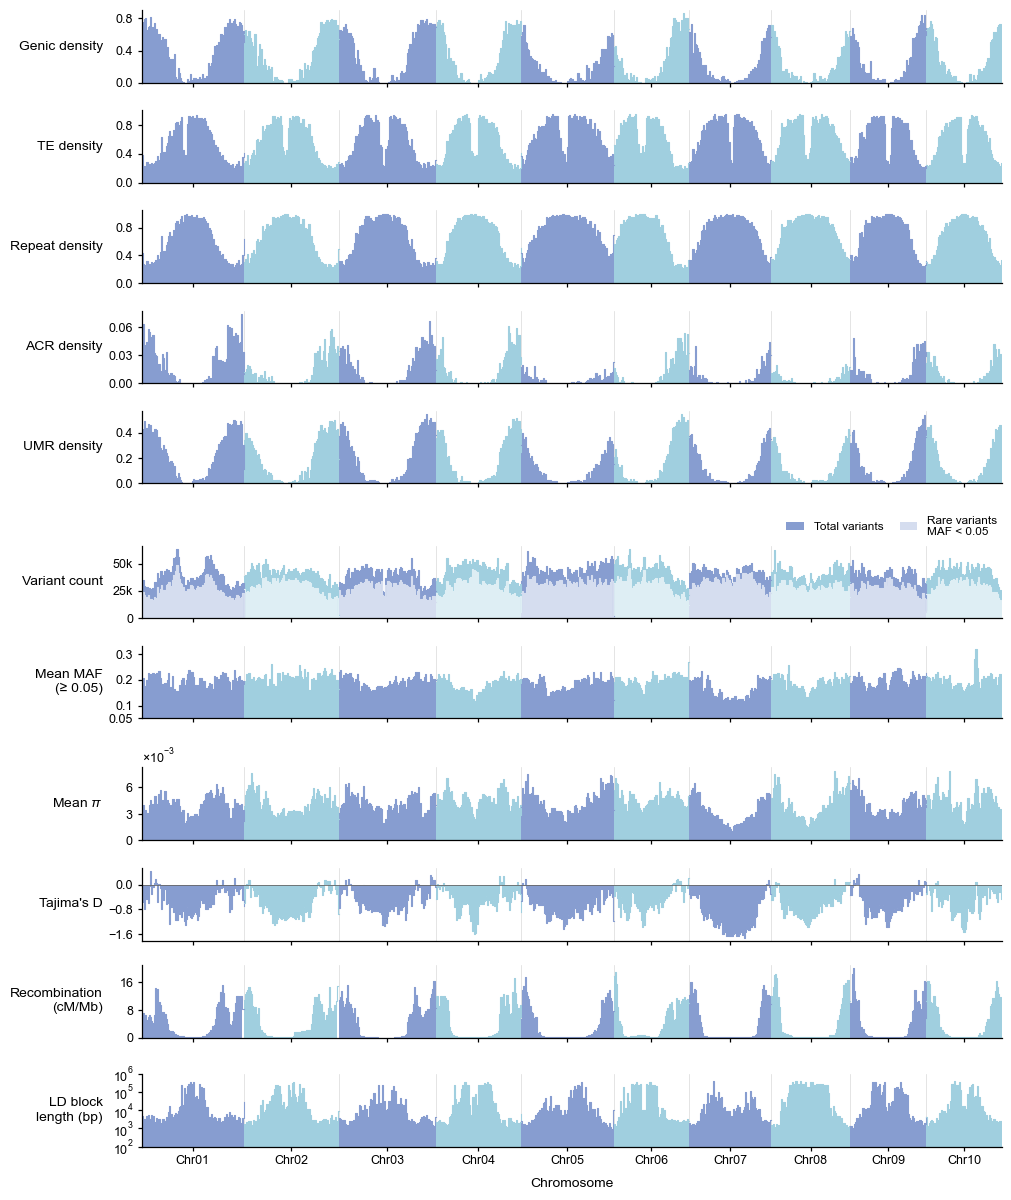

pdf: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_genome_tracks_1000000bp.pdf
png: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_genome_tracks_1000000bp.png
csv: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_genome_tracks_1000000bp.csv.gz


In [89]:
import matplotlib.pyplot as plt
from src.contexts import plot_genome_tracks

track_df = pd.read_csv(track_data_csv)
plot_chromosomes = [f'Chr{i:02d}' for i in range(1, 11)]
track_df = track_df[track_df['CHROM'].isin(plot_chromosomes)].copy()
track_plot = plot_genome_tracks(
    track_df, output_prefix=track_output_prefix, rare_maf_threshold=rare_maf_threshold,
    maf_ymin=0.05, ld_ylim=(1e2, 1e6), figsize=(10, 12),
    hspace=0.1, h_pad=0.1, label_fontsize=10, tick_fontsize=9, title_fontsize=12,
)
track_fig, track_axes = track_plot['figure'], track_plot['axes']
track_plot_df = track_plot['plot_data']
plt.show()
for kind, file_path in track_plot['files'].items():
    print(f'{kind}: {file_path}')


**图 6. 高粱地方品种的群体基因组特征。** 在十条染色体上以 1 Mb 窗口汇总基因组特征和群体遗传学统计量。各轨道从上至下依次展示基因、转座元件（TE）、重复序列、开放染色质区域（ACR）和未甲基化区域（UMR）的密度，以及变异数量、平均次要等位基因频率（MAF）、核苷酸多样性（π）、Tajima’s D、重组率和 PLINK 定义的连锁不平衡（LD）区块的平均长度。变异数量轨道中的浅色部分表示稀有变异（MAF <0.05）。


### 1.3 地方品种群体的环境特征

描述地方品种采集地的环境、环境变量之间的相关性，以及环境与基因型变异的关系.


#### 1.3.1 环境变量及其地理分布

In [90]:
environment_metadata_csv = f'{source_dir}/envir_metadata.csv'
environment_metadata_df = pd.read_csv(environment_metadata_csv)
environment_ids = environment_metadata_df['env_id'].tolist()
key_environment_ids = ['bio18', 'gsl', 'al', 'striga']
landraces_env_df = landrace_metadata_df.set_index('LIB')[environment_ids].copy()
environment_metadata_df


,env_id,env_abbr,category,short description,description,source,units,scale,note,Reference DOI
0,bio1,TMA,Temperature,Mean.Tmp.Annual,Annual Mean Temperature,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
1,bio2,TRD,Temperature,Mean.Diurnal.Range,Mean Diurnal Range,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
2,bio3,ISO,Temperature,Isothermality,Isothermality,CHELSA V2.1,%,NaN,NaN,10.1038/sdata.2017.122
3,bio4,TSE,Temperature,Tmp.Seasonality,Temperature Seasonality,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
4,bio7,TAR,Temperature,Tmp.Annual.Range,Temperature Annual Range,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
5,bio8,TWQ,Temperature,Mean.Tmp.Wet.Q,Mean Temperature of Wettest Quarter,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
6,bio9,TDQ,Temperature,Mean.Tmp.Dry.Q,Mean Temperature of Driest Quarter,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
7,bio10,THQ,Temperature,Mean.Tmp.Warm.Q,Mean Temperature of Warmest Quarter,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
8,bio11,TCQ,Temperature,Mean.Tmp.Cold.Q,Mean Temperature of Coldest Quarter,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
9,bio15,PSE,Precipitation,Prec.Seasonality,Precipitation Seasonality,CHELSA V2.1,mm,10.0,NaN,10.1038/sdata.2017.122


- 关键环境变量的地理分布

展示地方品种采集地的 `gsl`、`bio18`、`al` 和 `striga`。同时按 `gsl` 为遗传树着色，对照环境变化与遗传关系。


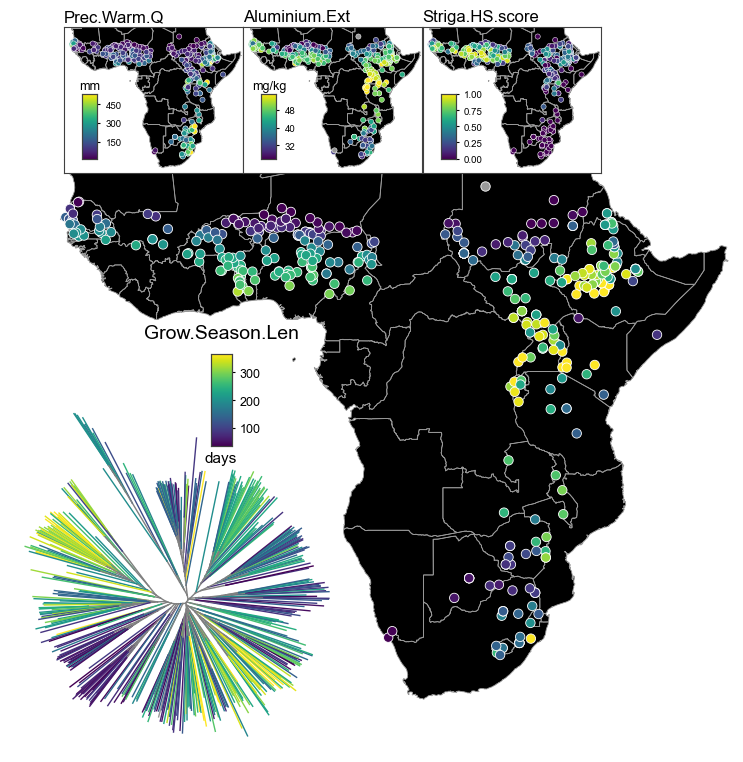

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_env_vars_map.fig1.pdf


In [91]:
import matplotlib.pyplot as plt
from src.env_vars import env_vars_map_plotter

main_env = 'gsl'
small_envs = ['bio18', 'al', 'striga']
longitude_limit = (-20, 52)
latitude_limit = (-37, 22)
# Tree anchor in main-map Axes coordinates; rotation in degrees.
tree_position = (-0.12, -0.07)
tree_rotate_deg = -55.0
world_map_shp = f'{source_dir}/natural_earth/ne_10m_admin_0_countries/ne_10m_admin_0_countries.shp'
save_fig_path = f'{results_dir}/landraces_env_vars_map.fig1.pdf'

environment_map_fig, environment_map_ax = env_vars_map_plotter(
    main_env, small_envs, landrace_metadata_df, nj_tree_file,
    environment_metadata_df, save_fig_path, world_map_shp,
    longitude_limit=longitude_limit, latitude_limit=latitude_limit,
    tree_position=tree_position, tree_rotate_deg=tree_rotate_deg,
)
plt.show()
print(f'Figure: {save_fig_path}')


**图 7. 高粱地方品种采集地关键环境变量的地理分布。** 地图展示 生长季长度、最暖季度降水量、可提取铝含量 和 独脚金 HS 评分。邻接树按 生长季长度 着色，用于对照环境变化与遗传关系。



#### 1.3.2 环境与基因型变异的关系

使用冗余分析（RDA）概括与环境变量相关的基因型变异。


In [92]:
from src.env_vars import rda_analysis

rda_output_dir = f'{results_dir}/RDA/{kinship_tag}'
rda_samples_csv = f'{rda_output_dir}/rda_samples.csv'
rda_env_contrib_csv = f'{rda_output_dir}/rda_env_contrib.csv'
rda_explained_csv = f'{rda_output_dir}/rda_explained.csv'
rda_result_files = [rda_samples_csv, rda_env_contrib_csv, rda_explained_csv]

stage_start = perf_counter()
if all(os.path.exists(file_path) for file_path in rda_result_files):
    print(f'[{datetime.now():%H:%M:%S}] Reusing RDA results: {rda_output_dir}', flush=True)
else:
    print(f'[{datetime.now():%H:%M:%S}] Calculating environmental RDA', flush=True)
    rda_analysis(
        vcf=snp_pruned_vcf_file, landraces_env_df=landraces_env_df,
        output_dir=rda_output_dir,
    )
rda_explained_df = pd.read_csv(rda_explained_csv, index_col=0)
r2_adj = rda_explained_df.loc[rda_explained_df['RDA'] == 'R2_adj', 'explained_variance'].iloc[0]
print(f'Adjusted R-squared: {r2_adj:.4f}')
print(f'[{datetime.now():%H:%M:%S}] RDA results ready ({perf_counter() - stage_start:.1f} s)', flush=True)


[23:49:14] Reusing RDA results: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/RDA/landraces.snp_pruned.maf0.01.win15kb.step50.r20.5
Adjusted R-squared: 0.1536
[23:49:14] RDA results ready (0.0 s)


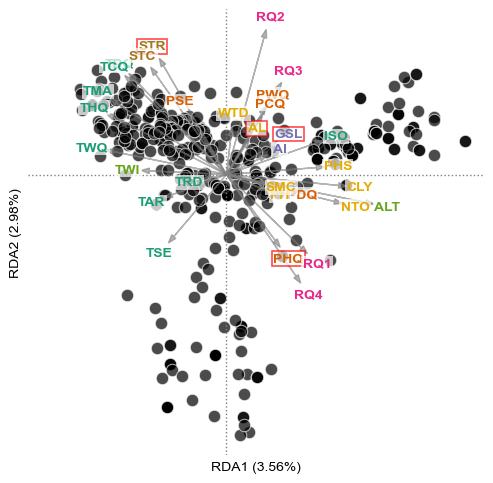

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_env_rda.fig1.pdf


In [93]:
import matplotlib.pyplot as plt
from src.env_vars import plot_rda_biplot

rda_samples_df = pd.read_csv(rda_samples_csv, index_col=0)
rda_env_contrib_df = pd.read_csv(rda_env_contrib_csv, index_col=0)
rda_explained_df = pd.read_csv(rda_explained_csv, index_col=0)
save_fig_path = f'{results_dir}/landraces_env_rda.fig1.pdf'
rda_fig, rda_ax = plot_rda_biplot(
    rda_samples_df, rda_env_contrib_df, rda_explained_df, environment_metadata_df,
    save_fig_path, highlight_env_ids=key_environment_ids,
)
plt.show()
print(f'Figure: {save_fig_path}')


**图 8. 冗余分析。** 高粱地方品种在冗余分析（RDA）前两个轴上的分布。箭头表示环境变量的方向及相对贡献。


#### 1.3.3 环境变量之间的相关性

使用环境信息完整的样本，计算环境变量之间的 Pearson 相关系数，描述它们的共同变化。


In [94]:
correlation_csv = f'{results_dir}/env_correlation_matrix.csv'
if os.path.exists(correlation_csv):
    environmental_corr_df = pd.read_csv(correlation_csv, index_col=0)
    print(f'Reusing environmental correlations: {correlation_csv}')
else:
    environmental_corr_df = landraces_env_df.dropna().corr(method='pearson')
    environmental_corr_df.to_csv(correlation_csv)
print(f'Environmental variables: {len(environmental_corr_df):,}')

Reusing environmental correlations: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/env_correlation_matrix.csv
Environmental variables: 31


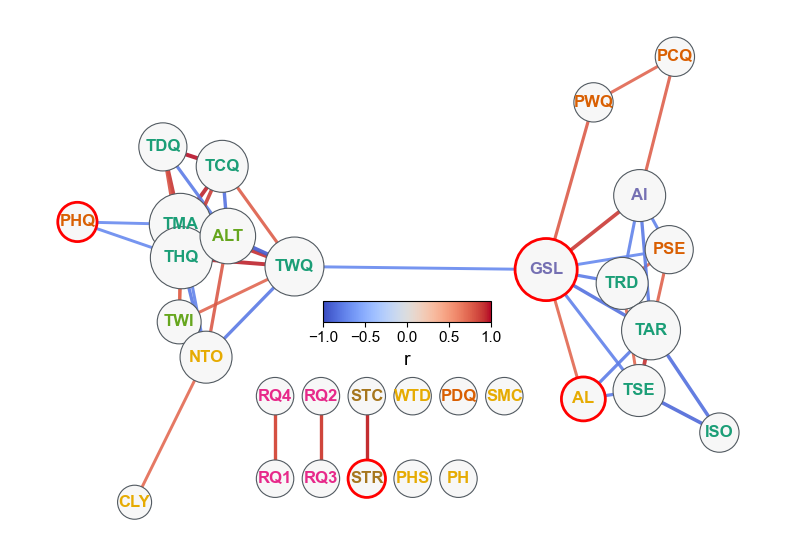

Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/env_network_custom_layout.fig1.pdf


In [95]:
import matplotlib.pyplot as plt
from src.env_vars import plot_env_corr_network

environmental_corr_df = pd.read_csv(correlation_csv, index_col=0)
correlation_threshold = 0.7
save_fig_path = f'{results_dir}/env_network_custom_layout.fig1.pdf'
environment_network_fig, environment_network_ax = plot_env_corr_network(
    environment_metadata_df, landraces_env_df, r_threshold=correlation_threshold,
    save_fig_path=save_fig_path, highlight_env_ids=key_environment_ids,
    correlation_df=environmental_corr_df,
)
plt.show()
print(f'Figure: {save_fig_path}')


**图 9. 环境变量的相关性网络。** 节点表示环境变量，节点大小反映其在网络中的度；边表示变量之间的相关性，边的颜色反映相关方向和强度（仅展示 |r|>0.7 的相关性）。关键环境变量以红色突出显示。


## 2. 环境 GWAS

以采集地点的环境测量值为表型，识别与环境相关的遗传变异。GEMMA 使用纳入 PLINK SNP 协方差亲缘矩阵的线性混合模型；MAGMA 将位点关联汇总至基因层面。



### 2.1 关联分析输入

使用全基因组范围和 CDS 范围的变异，以及由 LD-pruned SNP 计算的亲缘矩阵。按样本身份对齐基因型与环境测量值，排除缺少当前受检环境值的样本。



In [24]:
from src.gwas import GEMMA_JOB, MAGMA_JOB, prepare_gemma_phenotype_file
from src.vcf import get_sample_list_from_vcf
from tqdm.auto import tqdm

genome_fasta_file = f'{source_dir}/Sbicolor_730_v5.0.fa.gz'
gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
landraces_qc_vcf_file = f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz'
landraces_cds_vcf_file = f'{results_dir}/landraces_cds_maf0.01_het0.05.vcf.gz'
gwas_dir = f'{results_dir}/gwas'
gwas_workers = project_config['resources']['environmental_gwas']['cores']
magma_workers = project_config['resources']['environmental_gwas']['cores']
gwas_memory_gb = project_config['resources']['environmental_gwas']['memory_gb']
plink_threads = project_config['resources']['interactive']['cores']
gemma_block_size = 5_000_000
gemma_lmm = 4
plink_memory_mb = 16000
# Prevent reuse of associations fitted with a different kinship matrix.
kinship_source_file = f'{gwas_dir}/kinship_source.txt'
kinship_signature = f'{kinship_file}\t{os.path.getsize(kinship_file)}\t{os.stat(kinship_file).st_mtime_ns}'
if os.path.exists(kinship_source_file):
    with open(kinship_source_file) as handle:
        previous_kinship_signature = handle.read().strip()
    if previous_kinship_signature != kinship_signature:
        raise ValueError('GWAS kinship changed; move the existing gwas directory before rerunning.')
elif os.path.exists(gwas_dir) and any(os.scandir(gwas_dir)):
    raise ValueError('Existing GWAS results have no kinship provenance; move the gwas directory before rerunning.')
os.makedirs(gwas_dir, exist_ok=True)
with open(kinship_source_file, 'w') as handle:
    handle.write(kinship_signature + '\n')

# BIMBAM phenotypes and kinship rows must follow the genotype sample order.
gwas_sample_ids = get_sample_list_from_vcf(landraces_qc_vcf_file)
if gwas_sample_ids != get_sample_list_from_vcf(landraces_cds_vcf_file):
    raise ValueError('Genome and CDS VCF sample orders differ.')
kinship_sample_ids = pd.read_csv(kinship_id_file, sep=r'\s+', header=None, dtype=str)[1].tolist()
if gwas_sample_ids != kinship_sample_ids or gwas_sample_ids != get_sample_list_from_vcf(snp_pruned_vcf_file):
    raise ValueError('GWAS VCF and kinship-source VCF sample orders differ.')
if landrace_metadata_df['LIB'].duplicated().any():
    raise ValueError('Landrace metadata contains duplicate sample IDs.')
gwas_phenotype_df = landrace_metadata_df.set_index('LIB').loc[gwas_sample_ids, environment_ids]

envGWAS_job_dict = {}
for env_name in tqdm(environment_ids, desc='Preparing environmental GWAS', unit='variable'):
    env_job_dir = f'{gwas_dir}/{env_name}'
    os.makedirs(env_job_dir, exist_ok=True)
    pheno_file = prepare_gemma_phenotype_file(env_name, gwas_phenotype_df, f'{env_job_dir}/pheno.bimbam')
    envGWAS_job_dict[env_name] = {
        'site': GEMMA_JOB(env_name, env_job_dir, landraces_qc_vcf_file, pheno_file, kinship_file, lmm=gemma_lmm),
        'gene': MAGMA_JOB(
            env_name, env_job_dir, landraces_qc_vcf_file, gff_file,
            site_gwas_df_h5=f'{env_job_dir}/{env_name}.gemma/{env_name}.gemma.gwas_df.h5',
            phenotype_file=pheno_file, threads=plink_threads, memory_mb=plink_memory_mb, max_workers=magma_workers,
        ),
        'cds': GEMMA_JOB(f'{env_name}_cds', env_job_dir, landraces_cds_vcf_file, pheno_file, kinship_file, lmm=gemma_lmm),
    }
print(f'Prepared {len(envGWAS_job_dict):,} variables; samples: {len(gwas_sample_ids):,}')
print(f'GEMMA process limit: {gwas_workers}; total memory budget: {gwas_memory_gb} GB (not a hard limit)')
print(f'MAGMA batch process limit: {magma_workers}; environmental variables run sequentially')


Preparing environmental GWAS: 100%|██████████| 31/31 [00:00<00:00, 582.23variable/s]

Prepared 31 variables; samples: 443
GEMMA process limit: 80; total memory budget: 500 GB (not a hard limit)
MAGMA batch process limit: 80; environmental variables run sequentially


### 2.2 全基因组变异关联

使用 GEMMA 检验各环境变量与全基因组变异的关联，并控制亲缘关系（kinship）。对每个环境变量的有效 Wald P 值进行 Benjamini–Hochberg 校正。



In [ ]:
stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Starting genome-wide GEMMA with up to {gwas_workers} single-threaded workers; total memory budget {gwas_memory_gb} GB', flush=True)
for env_name in tqdm(environment_ids, desc='Genome-wide GEMMA', unit='variable'):
    site_job = envGWAS_job_dict[env_name]['site']
    site_job.run(block_size=gemma_block_size, max_workers=gwas_workers)
    if not os.path.exists(site_job.gwas_df_h5):
        raise RuntimeError(f'GEMMA result is incomplete: {site_job.gwas_df_h5}')
print(f'[{datetime.now():%H:%M:%S}] Genome-wide associations ready ({perf_counter() - stage_start:.1f} s)', flush=True)


### 2.3 基因层面的关联

使用 MAGMA 汇总基因及两侧各 2 kb 范围内的变异关联，并考虑 LD。分析四个重点环境变量，各变量的样本量采用其 GWAS 实际纳入的样本数。



In [ ]:
stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Starting MAGMA gene associations', flush=True)
for env_name in tqdm(key_environment_ids, desc='MAGMA gene associations', unit='variable'):
    site_job = envGWAS_job_dict[env_name]['site']
    if not os.path.exists(site_job.gwas_df_h5):
        raise RuntimeError(f'Run genome-wide GEMMA first: {site_job.gwas_df_h5}')
    gene_job = envGWAS_job_dict[env_name]['gene']
    gene_job.run()
    if not os.path.exists(gene_job.gwas_df_h5):
        raise RuntimeError(f'MAGMA result is incomplete: {gene_job.gwas_df_h5}')
print(f'[{datetime.now():%H:%M:%S}] Gene associations ready ({perf_counter() - stage_start:.1f} s)', flush=True)


### 2.4 编码变异关联

对 CDS 变异数据单独检验，考察涉及编码区变异的环境关联。



In [ ]:
stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Starting CDS GEMMA with up to {gwas_workers} single-threaded workers; total memory budget {gwas_memory_gb} GB', flush=True)
for env_name in tqdm(environment_ids, desc='CDS GEMMA', unit='variable'):
    cds_job = envGWAS_job_dict[env_name]['cds']
    cds_job.run(block_size=gemma_block_size, max_workers=gwas_workers)
    if not os.path.exists(cds_job.gwas_df_h5):
        raise RuntimeError(f'CDS GEMMA result is incomplete: {cds_job.gwas_df_h5}')
print(f'[{datetime.now():%H:%M:%S}] CDS associations ready ({perf_counter() - stage_start:.1f} s)', flush=True)


### 2.5 可视化

通过 Manhattan 图、QQ 图和 P 值直方图概括环境关联，展示四个重点环境变量进行比较。



In [28]:
import matplotlib.pyplot as plt
from src.gwas import plot_gwas_summary_panel

gwas_fdr_threshold = 0.05
gwas_histogram_bins = 50
gwas_plot_force_recompute = False
environment_descriptions = environment_metadata_df.set_index('env_id')['description'].to_dict()
for env_name in tqdm(environment_ids, desc='Plotting GWAS summaries', unit='variable'):
    gwas_result_h5 = f'{gwas_dir}/{env_name}/{env_name}.gemma/{env_name}.gemma.gwas_df.h5'
    gwas_png = gwas_result_h5.replace('.h5', '_gwas_summary.png')
    gwas_pdf = gwas_result_h5.replace('.h5', '_gwas_summary.pdf')
    gwas_plot_csv = gwas_result_h5.replace('.h5', '_gwas_summary.csv.gz')
    if gwas_plot_force_recompute or not all(os.path.exists(file_path) for file_path in [gwas_png, gwas_pdf, gwas_plot_csv]):
        summary_fig, summary_axes = plot_gwas_summary_panel(
            gwas_result_h5, genome_fasta_file, threshold_fdr=gwas_fdr_threshold,
            bins=gwas_histogram_bins, title=environment_descriptions[env_name], save=True,
        )
        plt.close(summary_fig)
print(f'GWAS summaries: {gwas_dir}')


Plotting GWAS summaries: 100%|██████████| 31/31 [00:00<00:00, 21131.71variable/s]

GWAS summaries: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/gwas


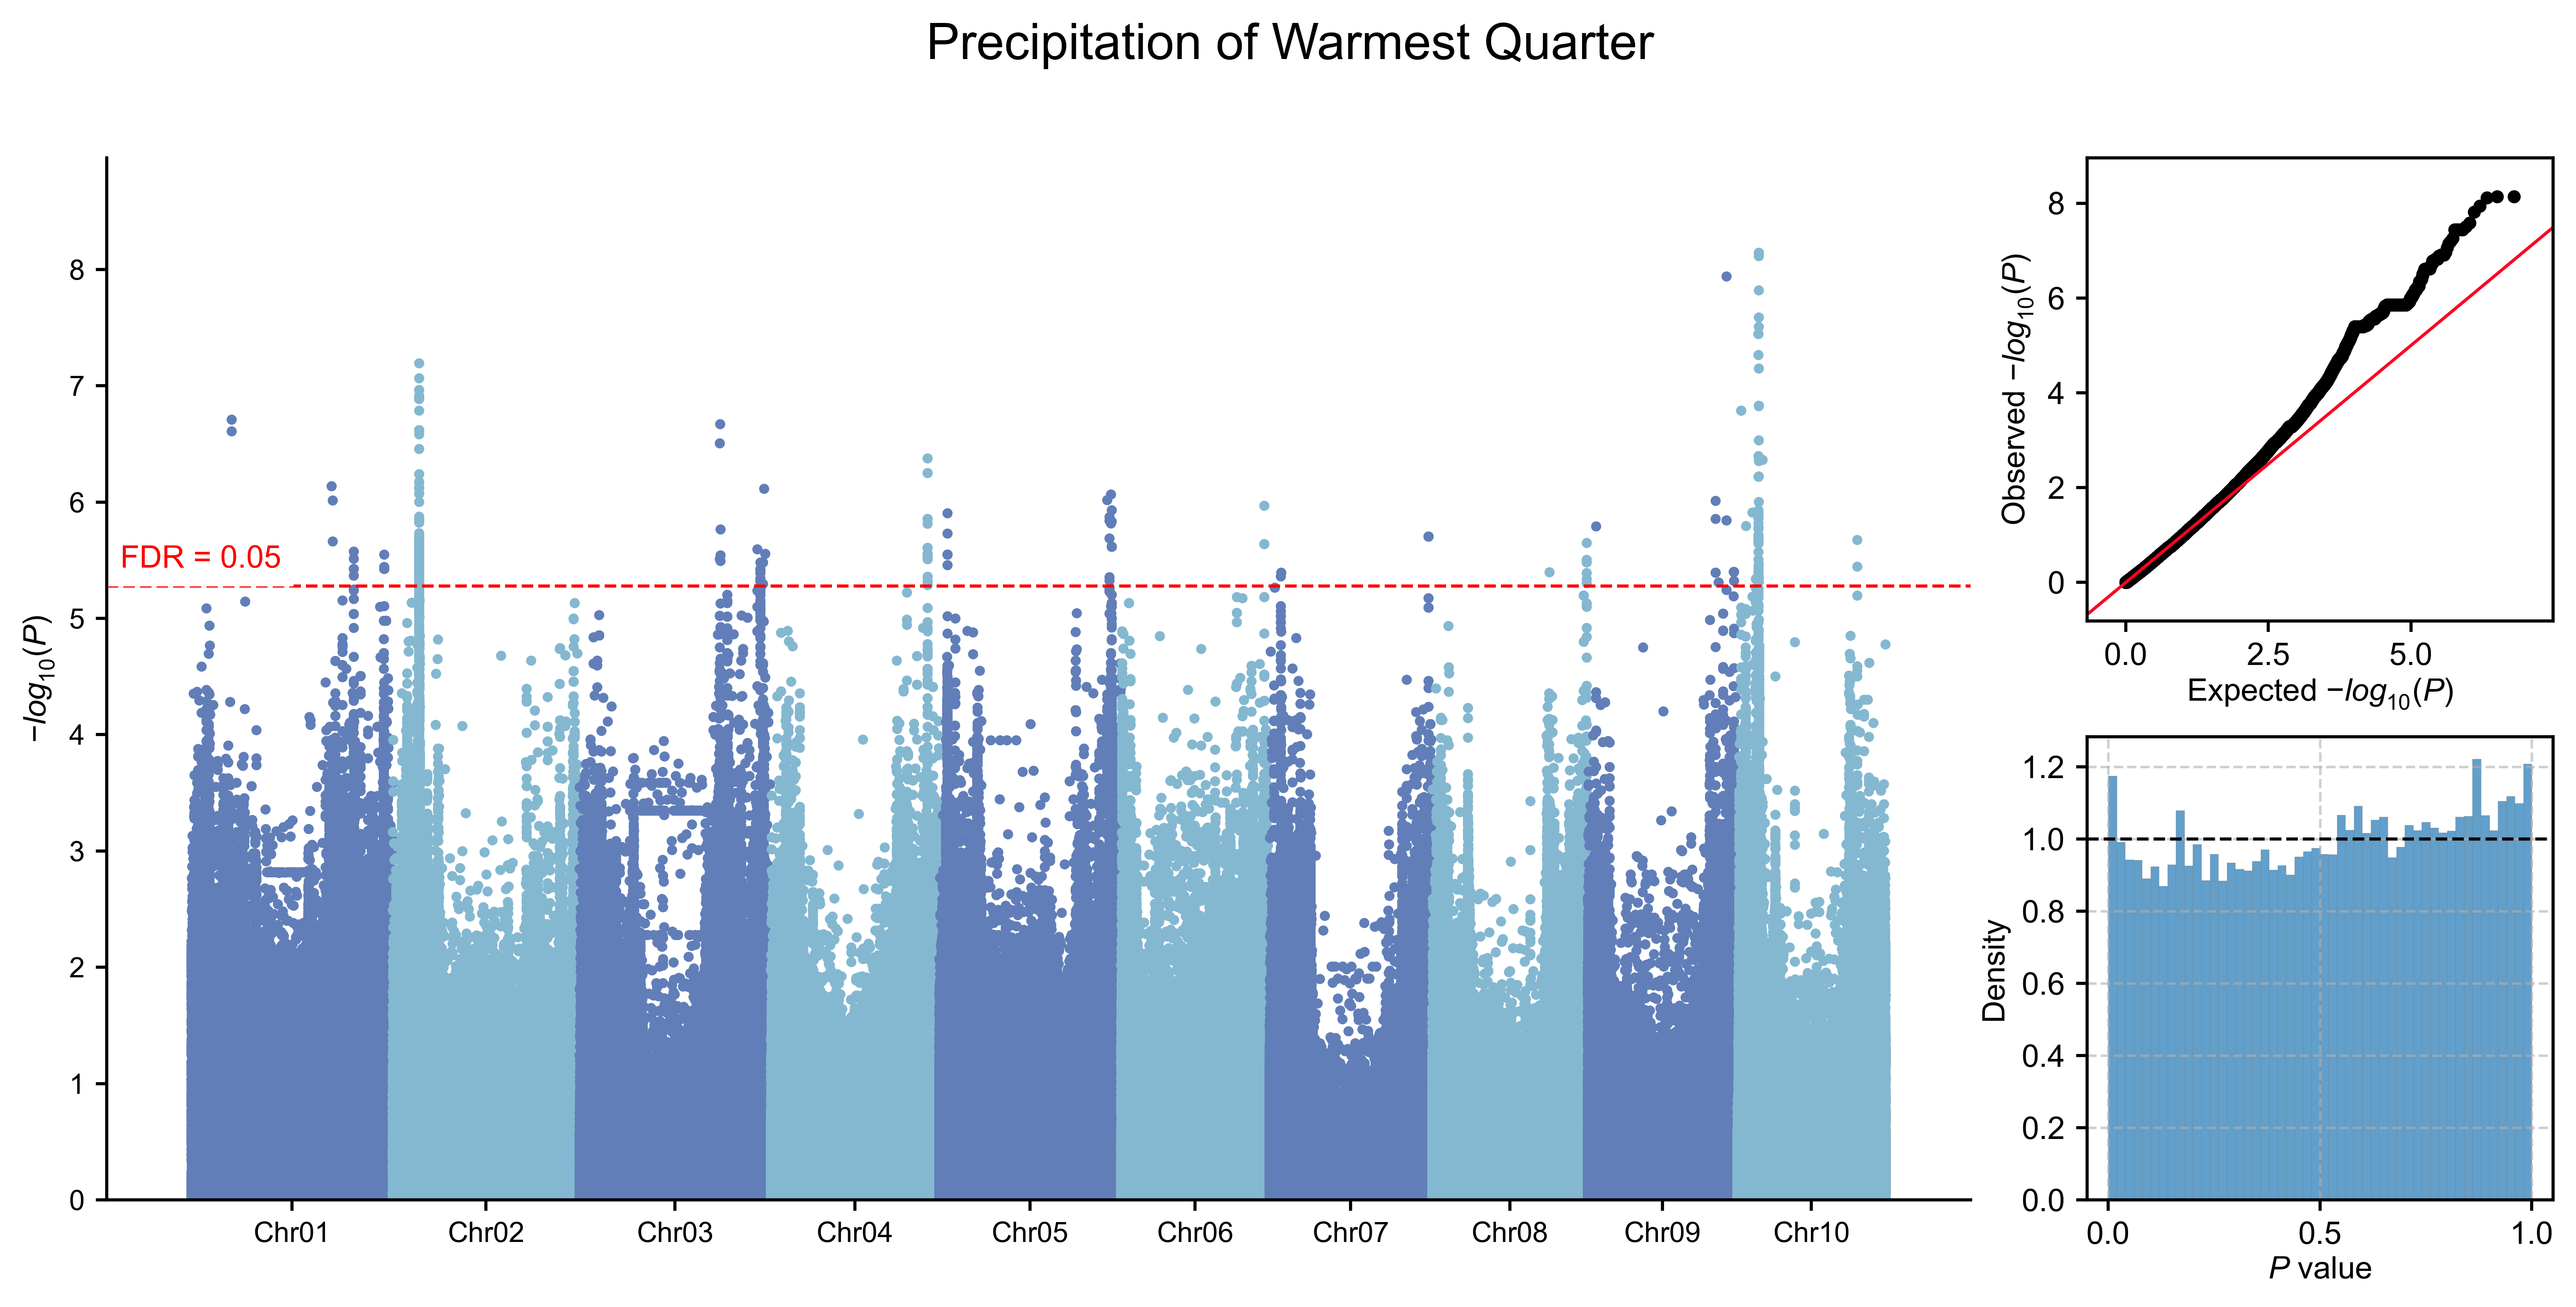

In [29]:
from IPython.display import Image, display

env_id = 'bio18'
gwas_result_h5 = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
gwas_png = gwas_result_h5.replace('.h5', '_gwas_summary.png')
display(Image(filename=gwas_png, width=1200))


**图 10. 最暖季度降水量的全基因组关联结果。** Manhattan 图展示全基因组范围的变异关联，每个点代表一个受检变异，按基因组位置与 −log10(*P*) 绘制。染色体以交替颜色表示，红色虚线标记假发现率（FDR）为 0.05 的阈值。分位数–分位数（QQ）图比较无关联零假设下观测与预期的 −log10(*P*) 值，红色对角线表示预期的零分布。直方图展示全部受检变异的原始 *P* 值分布，水平虚线表示均匀分布下的预期密度。



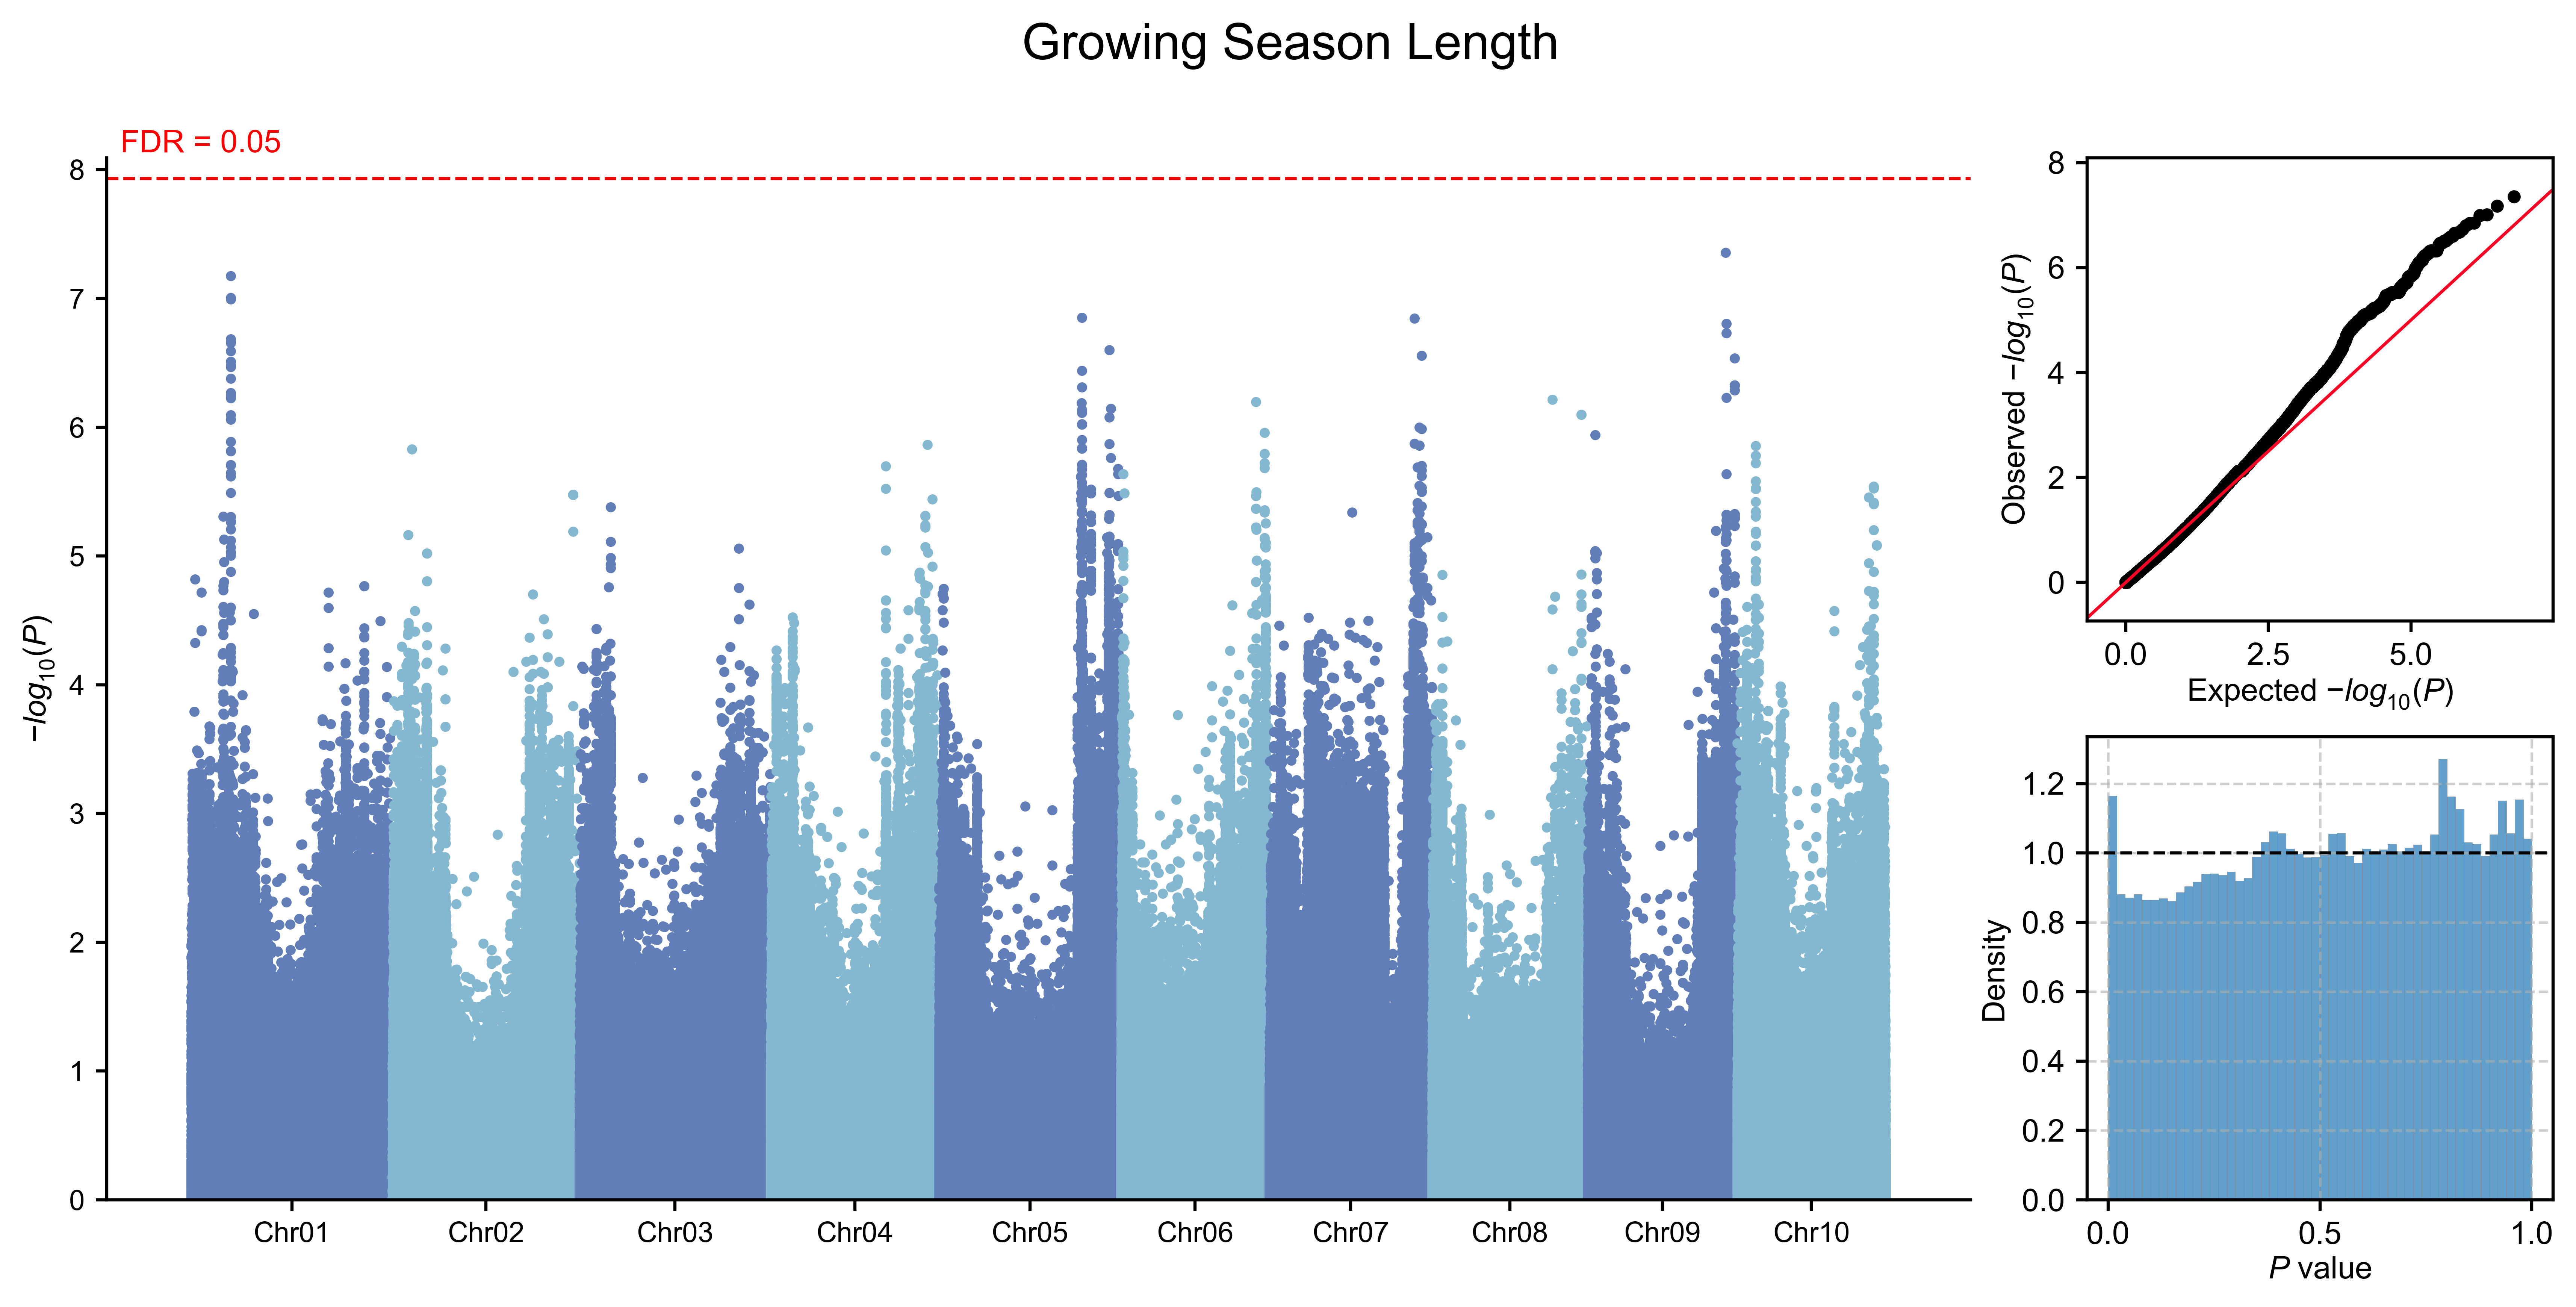

In [30]:
from IPython.display import Image, display

env_id = 'gsl'
gwas_result_h5 = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
gwas_png = gwas_result_h5.replace('.h5', '_gwas_summary.png')
display(Image(filename=gwas_png, width=1200))


**图 11. 生长季长度的全基因组关联结果。** Manhattan 图展示全基因组范围的变异关联，每个点代表一个受检变异，按基因组位置与 −log10(*P*) 绘制。染色体以交替颜色表示，红色虚线标记假发现率（FDR）为 0.05 的阈值。分位数–分位数（QQ）图比较无关联零假设下观测与预期的 −log10(*P*) 值，红色对角线表示预期的零分布。直方图展示全部受检变异的原始 *P* 值分布，水平虚线表示均匀分布下的预期密度。



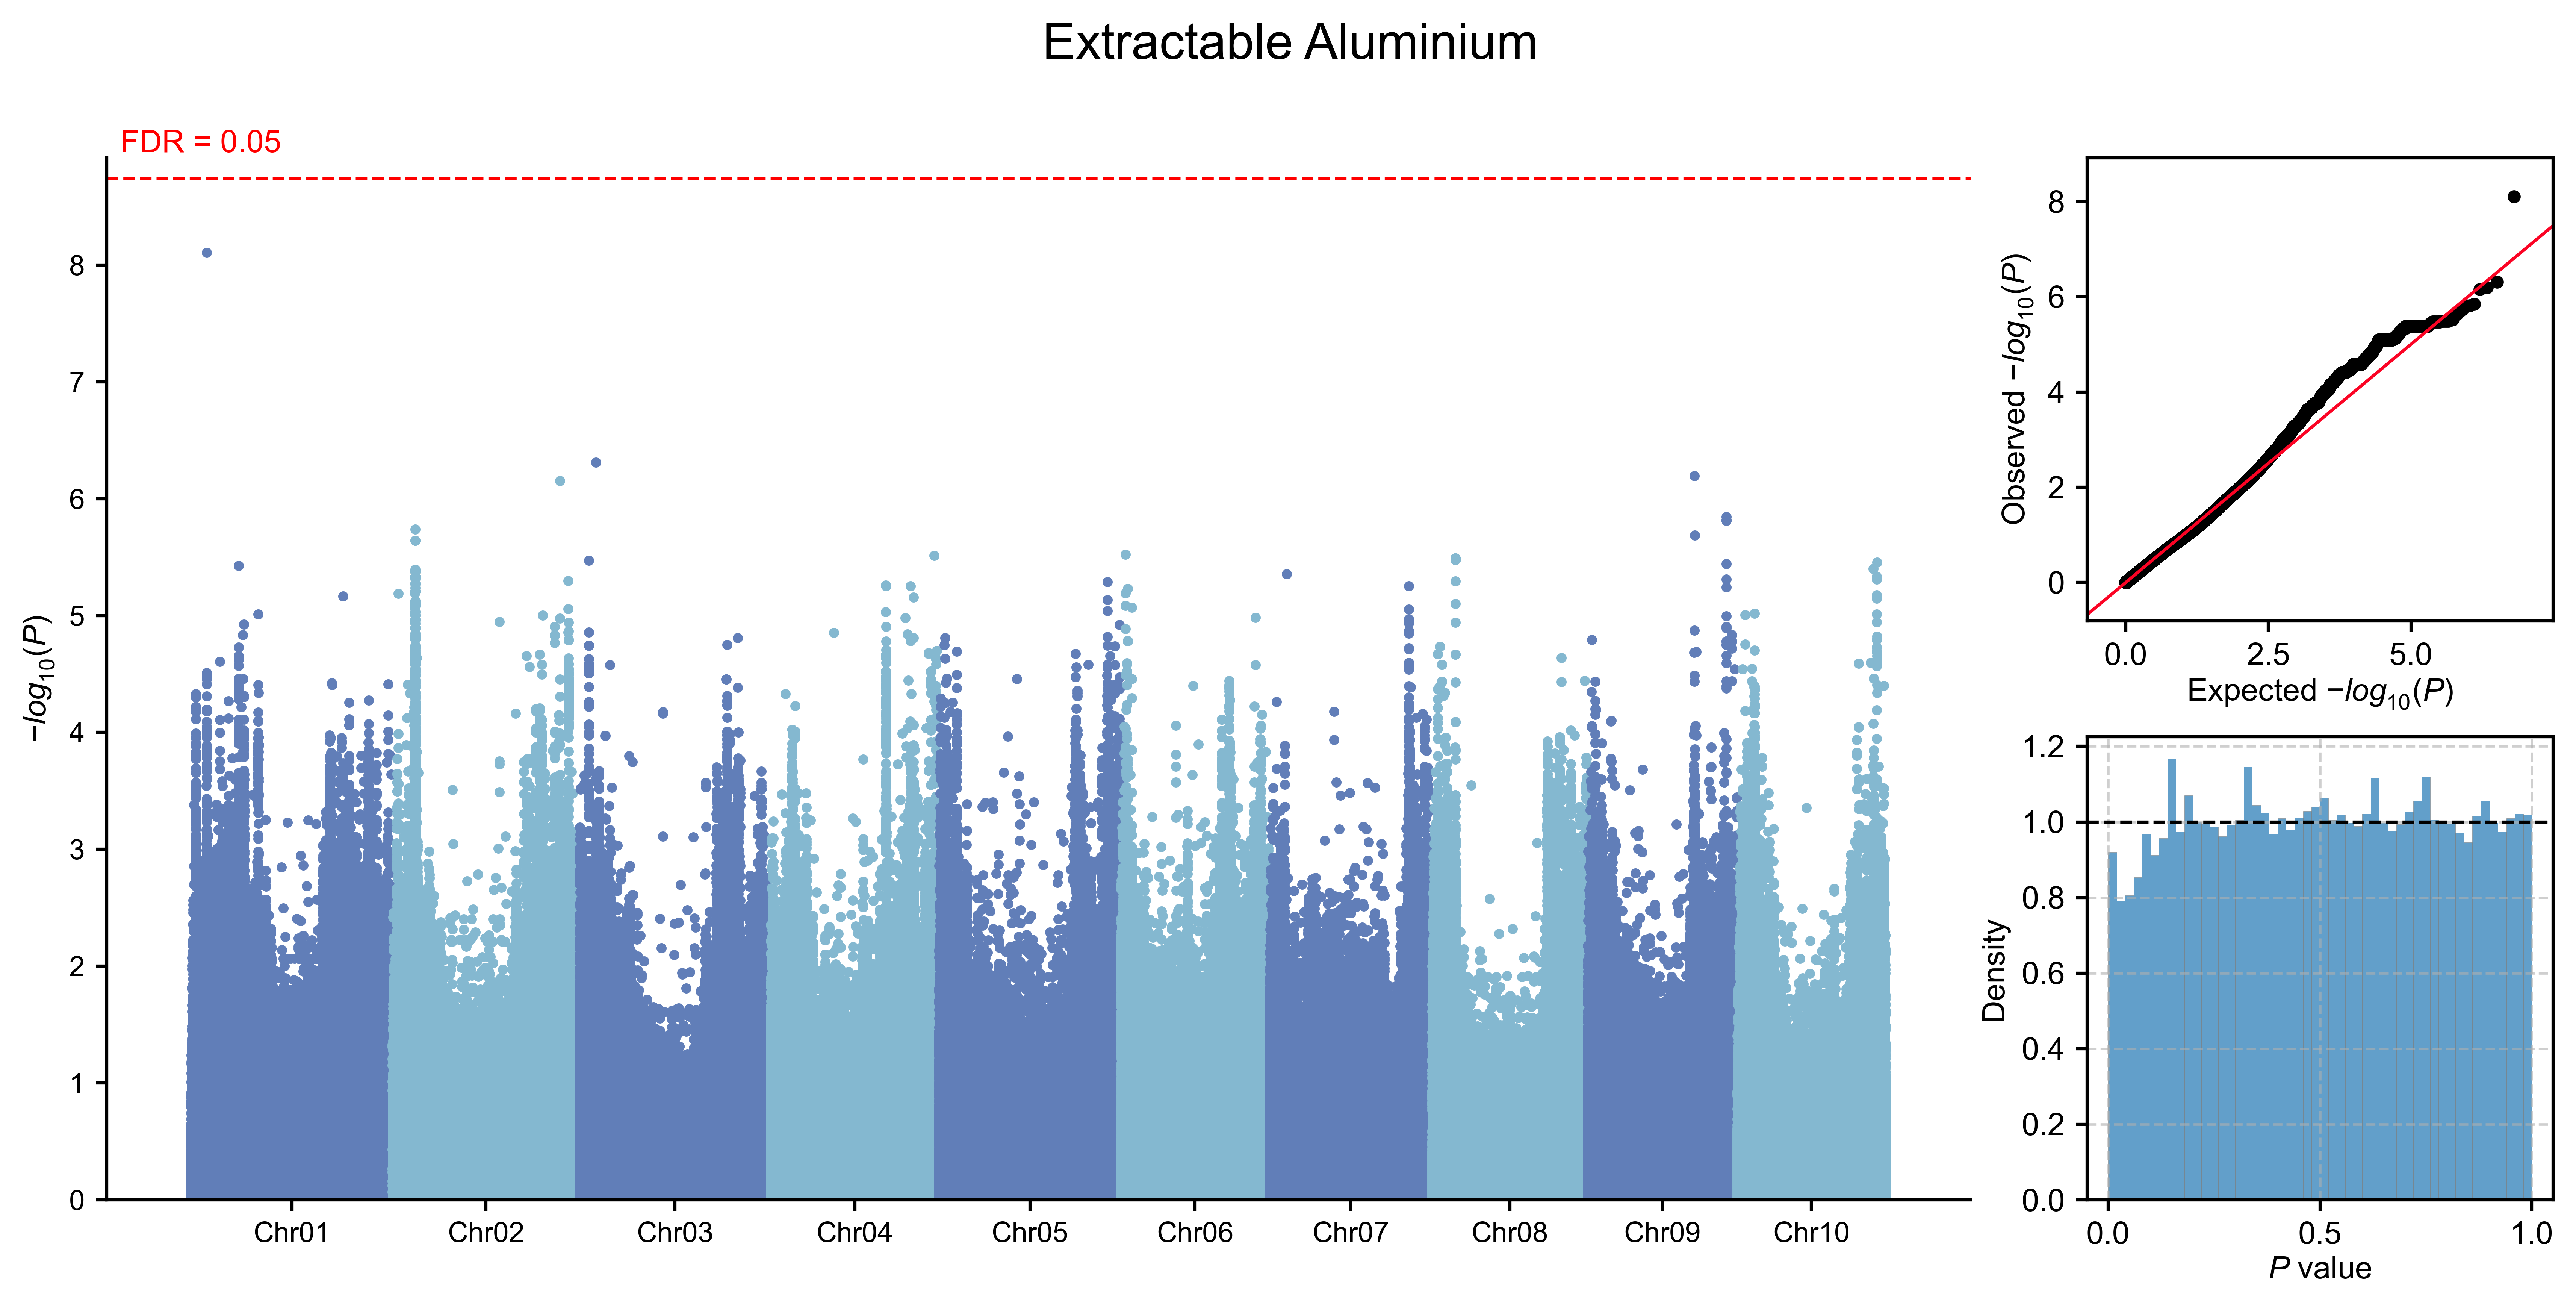

In [31]:
from IPython.display import Image, display

env_id = 'al'
gwas_result_h5 = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
gwas_png = gwas_result_h5.replace('.h5', '_gwas_summary.png')
display(Image(filename=gwas_png, width=1200))


**图 12. 可提取铝含量的全基因组关联结果。** Manhattan 图展示全基因组范围的变异关联，每个点代表一个受检变异，按基因组位置与 −log10(*P*) 绘制。染色体以交替颜色表示，红色虚线标记假发现率（FDR）为 0.05 的阈值。分位数–分位数（QQ）图比较无关联零假设下观测与预期的 −log10(*P*) 值，红色对角线表示预期的零分布。直方图展示全部受检变异的原始 *P* 值分布，水平虚线表示均匀分布下的预期密度。



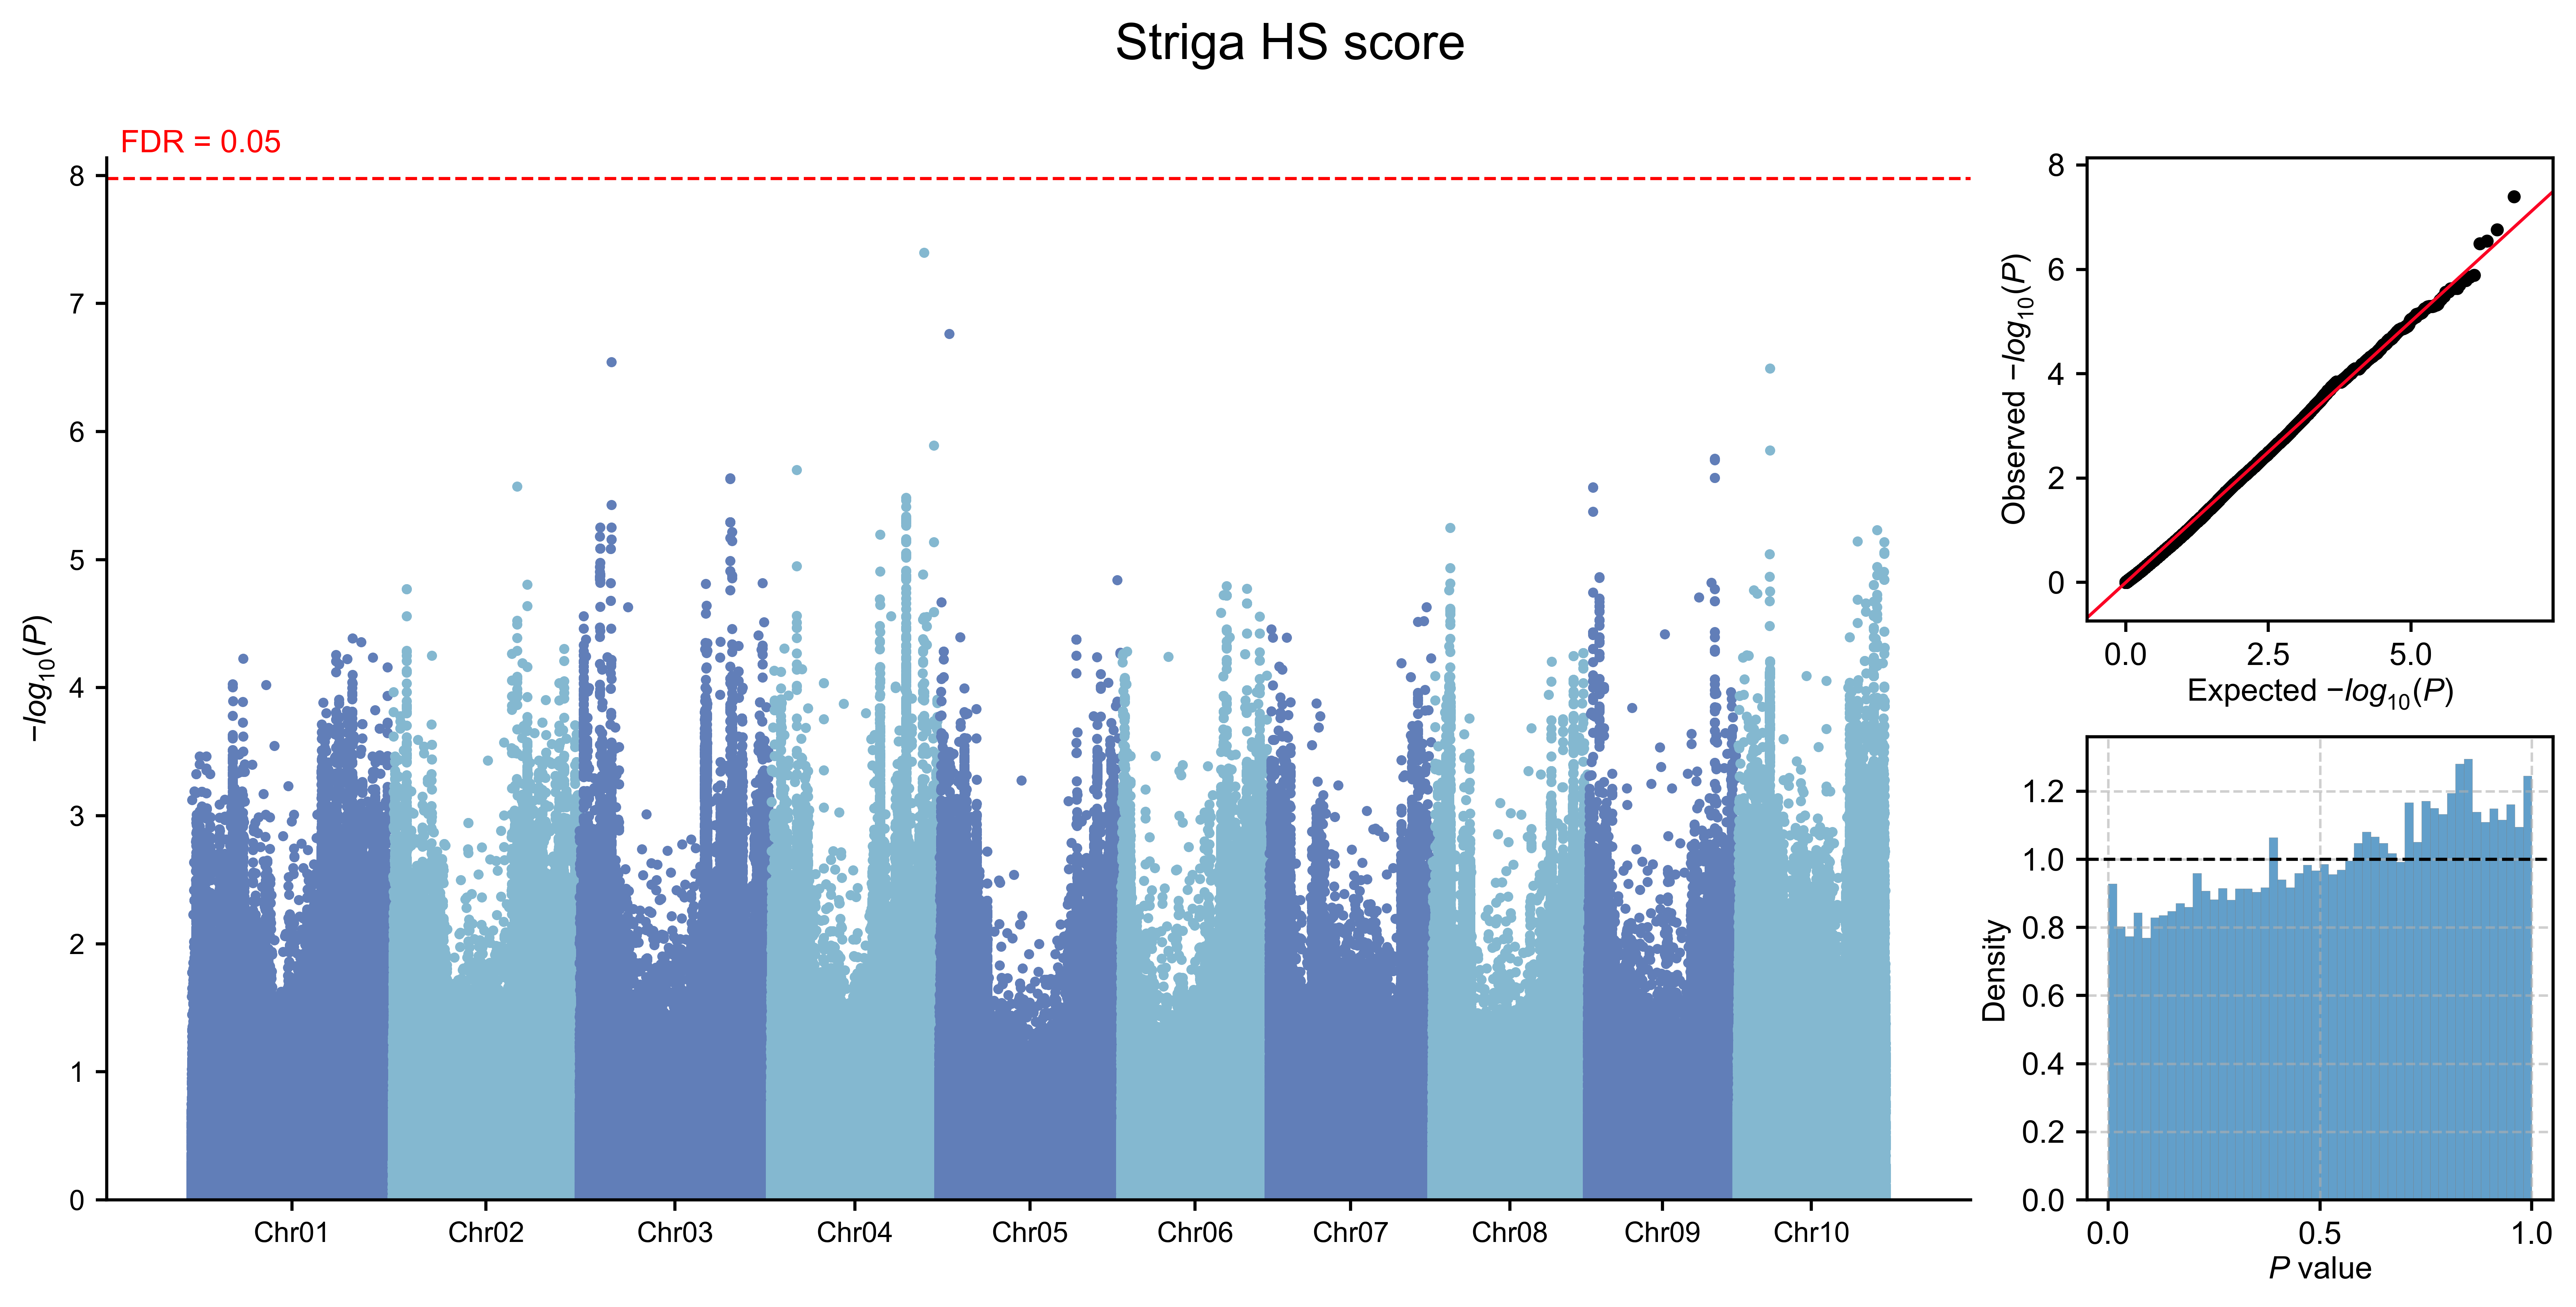

In [32]:
from IPython.display import Image, display

env_id = 'striga'
gwas_result_h5 = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
gwas_png = gwas_result_h5.replace('.h5', '_gwas_summary.png')
display(Image(filename=gwas_png, width=1200))


**图 13. 独脚金 HS 评分的全基因组关联结果。** Manhattan 图展示全基因组范围的变异关联，每个点代表一个受检变异，按基因组位置与 −log10(*P*) 绘制。染色体以交替颜色表示，红色虚线标记假发现率（FDR）为 0.05 的阈值。分位数–分位数（QQ）图比较无关联零假设下观测与预期的 −log10(*P*) 值，红色对角线表示预期的零分布。直方图展示全部受检变异的原始 *P* 值分布，水平虚线表示均匀分布下的预期密度。



## 3. 基因组特征与 GEA 信号沿染色体的分布

在 Chr01–Chr10 对齐的 1 Mb 窗口中，展示基因组特征与 GEA 信号沿染色体的分布。



### 3.1 基因组特征汇总

在 1 Mb 窗口中汇总基因组与表观基因组覆盖、基因类别及变异注释，并对各特征跨窗口标准化。群体遗传轨道沿用第 1.2.2 节



In [97]:
from src.contexts import (
    prepare_genomic_feature_landscape, prepare_gea_landscape, plot_genomic_gea_landscape,
)

window_size = 1_000_000
genome_tracks_csv = f'{results_dir}/landraces_genome_tracks_{window_size}bp.csv.gz'
landscape_prefix = f'{results_dir}/genomic_gea_landscape'
feature_summary_csv = f'{landscape_prefix}.features.csv.gz'
gea_enrichment_csv = f'{landscape_prefix}.gea.csv.gz'
cloned_bins_csv = f'{landscape_prefix}.cloned_bins.csv.gz'
environment_metadata_csv = f'{source_dir}/envir_metadata.csv'
correlation_csv = f'{results_dir}/env_correlation_matrix.csv'
force_recompute = False


In [98]:
feature_landscape = prepare_genomic_feature_landscape(
    genome_tracks_csv, f'{results_dir}/gene_contexts.h5',
    f'{results_dir}/site_contexts.genome.maf0.05.h5', f'{source_dir}/Sorghum_flowering_genes.csv',
    landscape_prefix, window_size=window_size, force_recompute=force_recompute,
)
print(f"Feature tracks: {feature_landscape['features']['TRACK'].nunique()}; "
      f"cloned genes: {len(feature_landscape['cloned_genes'])}")
feature_landscape['features'].head()


[00:39:15] Reusing feature landscape: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape
Feature tracks: 19; cloned genes: 14


,CHROM,START,END,PANEL,GROUP,TRACK,LABEL,CMAP,TRACK_ORDER,RAW_VALUE,Z_SCORE
0,Chr01,1,1000000,main,Genomic structure,GENIC_FRACTION,Genic,Oranges,0,0.617405,1.219262
1,Chr01,1000001,2000000,main,Genomic structure,GENIC_FRACTION,Genic,Oranges,0,0.760157,1.745702
2,Chr01,2000001,3000000,main,Genomic structure,GENIC_FRACTION,Genic,Oranges,0,0.795907,1.877540
3,Chr01,3000001,4000000,main,Genomic structure,GENIC_FRACTION,Genic,Oranges,0,0.808476,1.923892
4,Chr01,4000001,5000000,main,Genomic structure,GENIC_FRACTION,Genic,Oranges,0,0.654799,1.357164


### 3.2 GEA 信号的全基因组分布

以 1 Mb 窗口概括各环境变量的 GEA 信号在全基因组中的分布。使用关联信号较强变异的窗口富集 P 值的 −log10 作为指标，展示 GEA 信号的空间分布及其与基因组特征的对应关系。



In [99]:
top_fraction = 0.05
gea_landscape = prepare_gea_landscape(
    genome_tracks_csv, f'{results_dir}/gwas', environment_metadata_csv,
    landscape_prefix, window_size=window_size, top_fraction=top_fraction,
    force_recompute=force_recompute,
)
print(f"Environments: {gea_landscape['gea']['env_id'].nunique()}; "
      f"windows: {len(gea_landscape['gea'][['CHROM', 'START', 'END']].drop_duplicates())}")
gea_landscape['gea'].head()


[00:39:18] Reusing GEA landscape: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.gea.csv.gz
Environments: 31; windows: 722


,CHROM,START,END,env_id,N_TESTED,N_TOP,TOTAL_TESTED,TOTAL_TOP,TOP_P_THRESHOLD,P_VALUE,NEG_LOG10_P
0,Chr01,1,1000000,bio1,6162,849,6445964,322299,0.044524,1.252480e-152,151.902229
1,Chr01,1000001,2000000,bio1,9839,790,6445964,322299,0.044524,2.258414e-37,36.646196
2,Chr01,2000001,3000000,bio1,6003,688,6445964,322299,0.044524,1.134604e-87,86.945156
3,Chr01,3000001,4000000,bio1,8335,1027,6445964,322299,0.044524,2.163650e-150,149.664813
4,Chr01,4000001,5000000,bio1,7119,1171,6445964,322299,0.044524,7.867943e-277,276.104139


联合展示基因组特征与 GEA 信号的全基因组分布。



[00:39:25] Exported main landscape: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.main


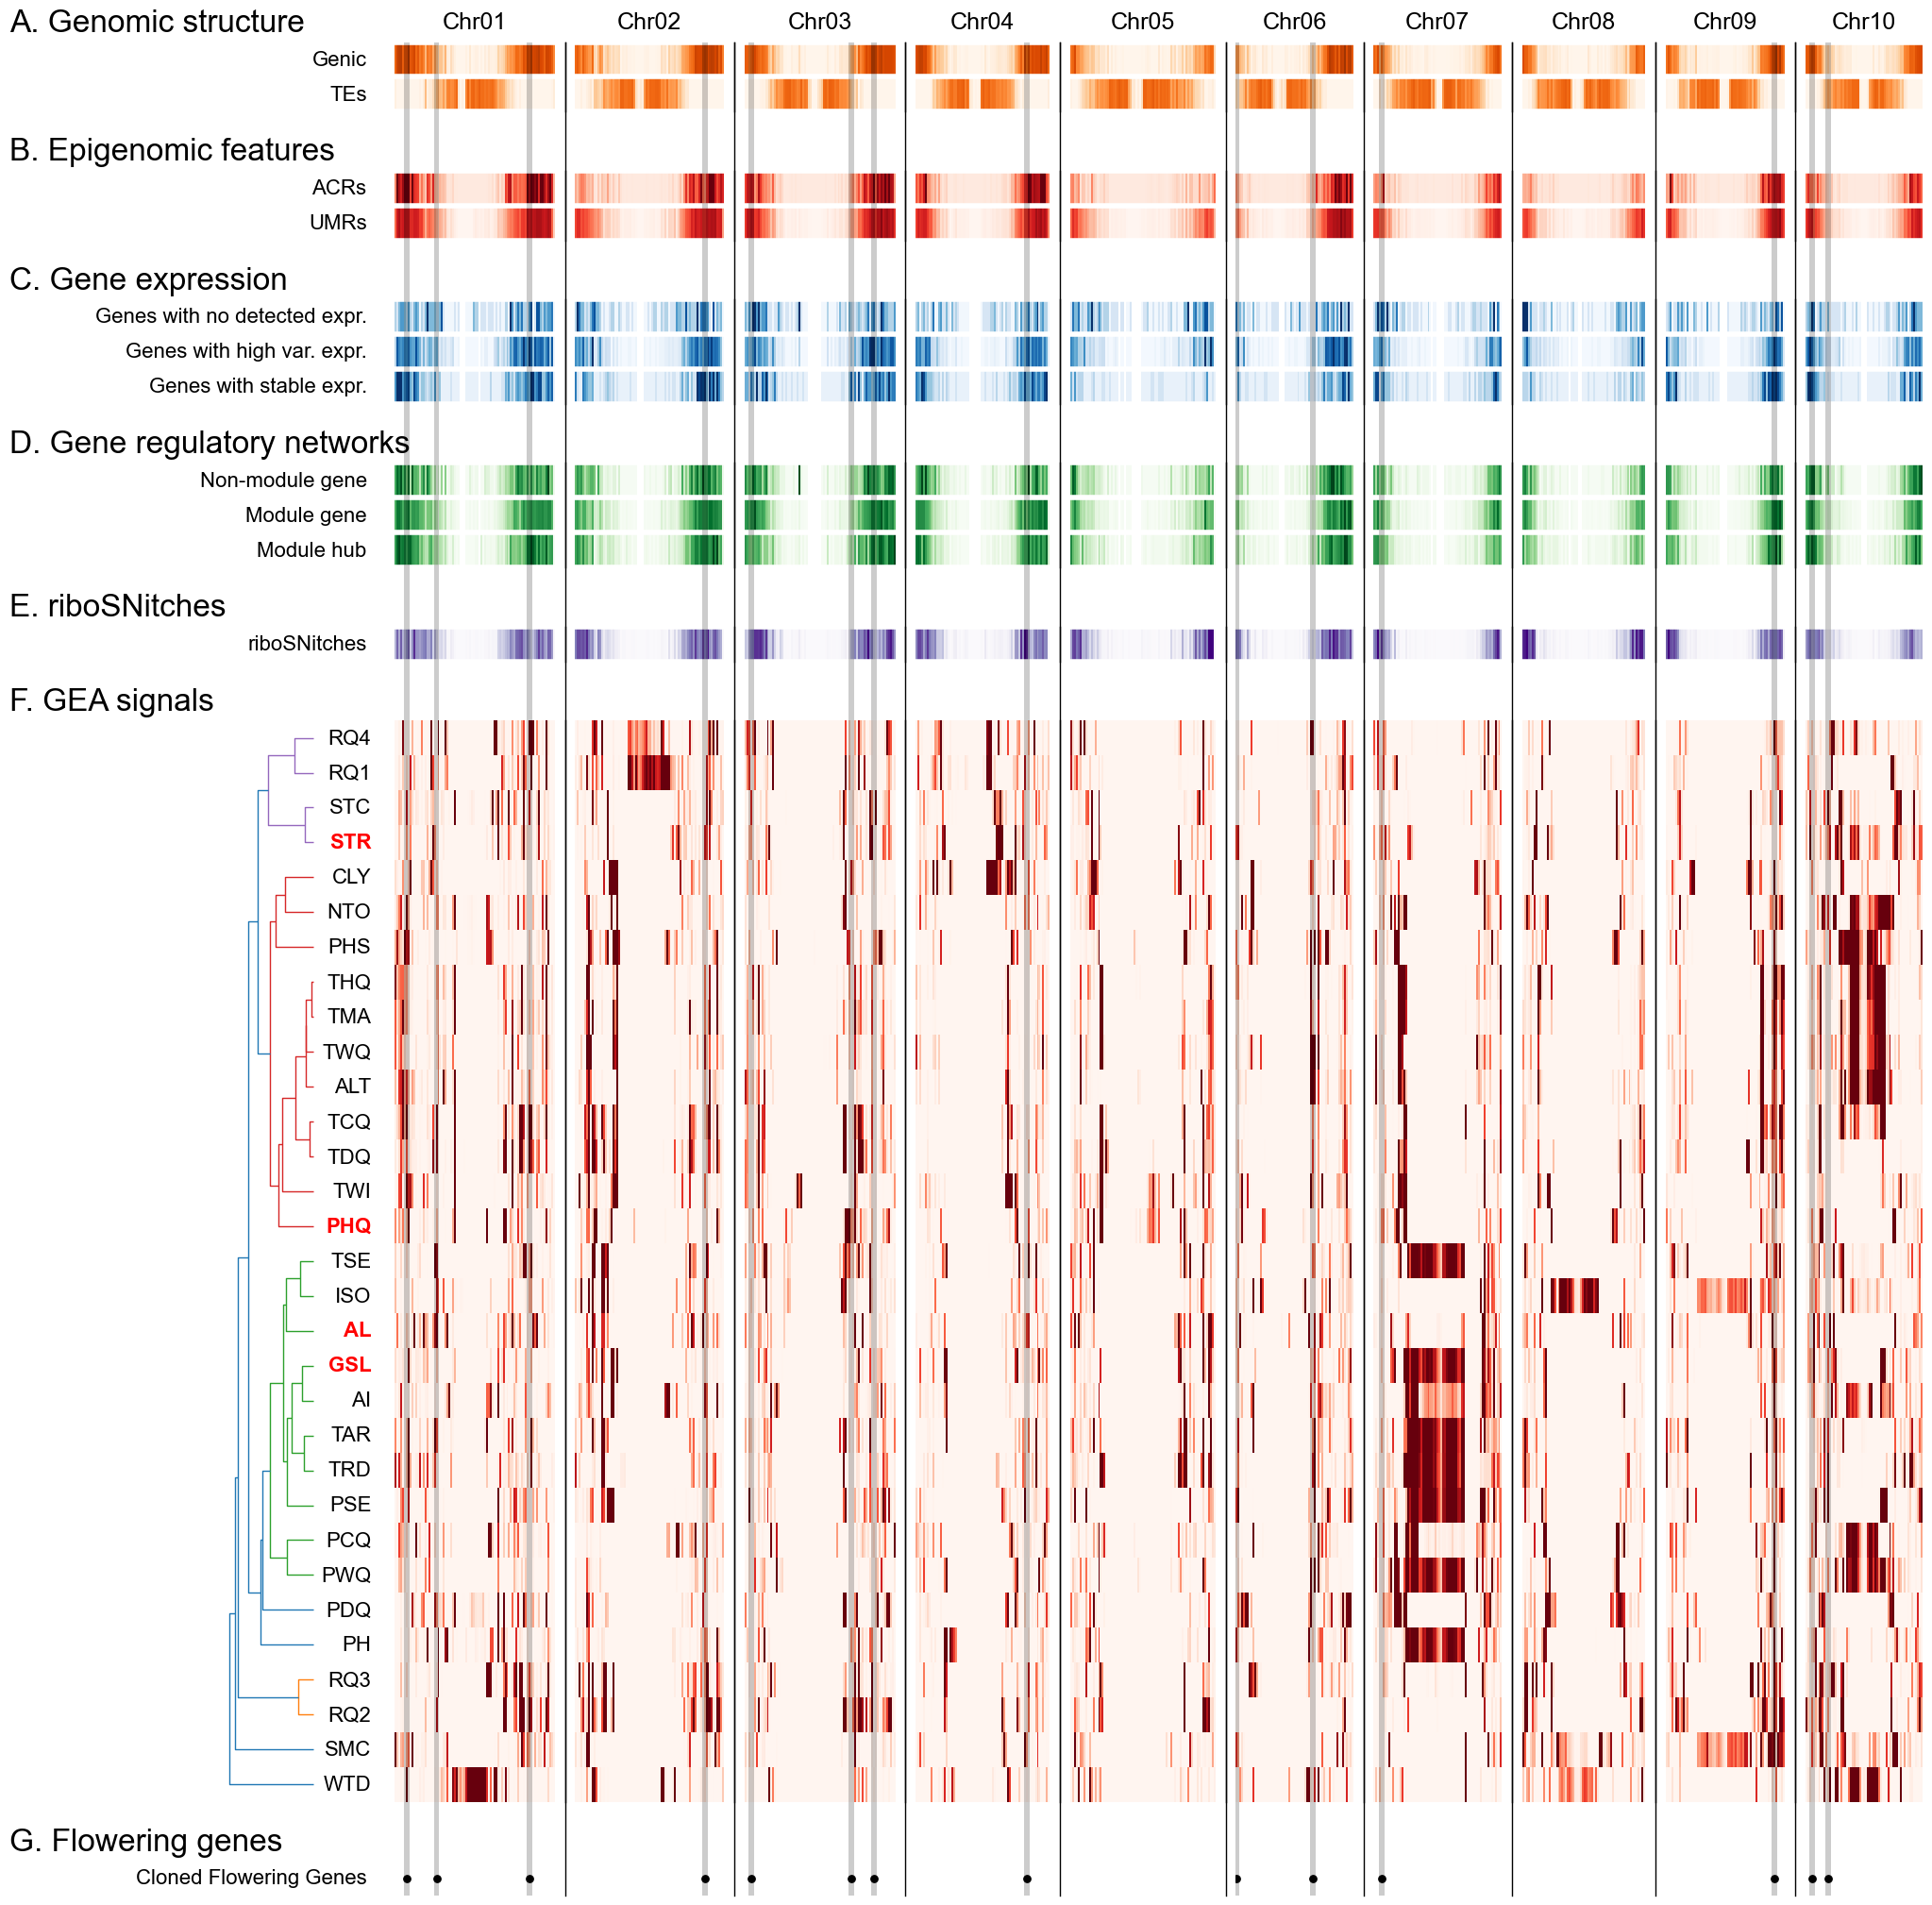

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.main.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.main.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.main.csv.gz'}


In [100]:
import matplotlib.pyplot as plt

figsize = (29.7 * 0.7, 21)
label_fontsize = 16
title_fontsize = 24
hspace = 0.275
wspace = 0.15

main_landscape_plot = plot_genomic_gea_landscape(
    feature_summary_csv, gea_enrichment_csv, cloned_bins_csv,
    environment_metadata_csv, correlation_csv, f'{landscape_prefix}.main',
    panel='main', window_size=window_size, figsize=figsize,
    label_fontsize=label_fontsize, title_fontsize=title_fontsize,
    hspace=hspace, wspace=wspace, highlight_env_ids=key_environment_ids,
)
plt.show()
print(main_landscape_plot['files'])


**图 14. 基因组特征与基因型–环境关联（GEA）的全基因组分布。** 将高粱的十条染色体（Chr01–Chr10）划分为 1 Mb 窗口，末端窗口保留真实基因组边界。特征轨道分别进行 Z-score 标准化，颜色越深表示数值越高（颜色范围 −1 至 2.5）。（A）基因组结构：包含两侧各 2 kb 的基因区域覆盖，以及转座元件覆盖。（B）表观基因组特征：染色质开放区域（ACR）和非甲基化区域（UMR）。（C）基因表达类别：未检测到表达、表达变异较高及稳定表达的基因。（D）基因调控网络类别：非模块基因、模块基因和模块枢纽基因。基因类别按基因中点计数；TE、ACR 和 UMR 覆盖采用区域并集比例。（E）全基因组范围变异中预测的 riboSNitch。（F）GEA 信号：每行代表一个环境变量，根据其在地方品种群体中的测量值相似性，以 1−|Pearson r| 为距离、采用 average linkage 聚类。颜色表示有效全基因组 Wald P 值不高于第 5 百分位数的变异（含阈值处并列值）的单侧超几何 P 值的 −log10，背景为全部具有有效 Wald P 值的变异。空窗口 P=1。GEA 数值不再按行进行 Z-score 标准化，共享颜色范围采用第 5 和第 95 百分位数。（G）黑点标记与已克隆开花基因本体重叠的窗口。灰色竖向带以这些标记为中心覆盖三个窗口，并贯穿上方轨道。



[00:39:57] Exported supp landscape: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.supp


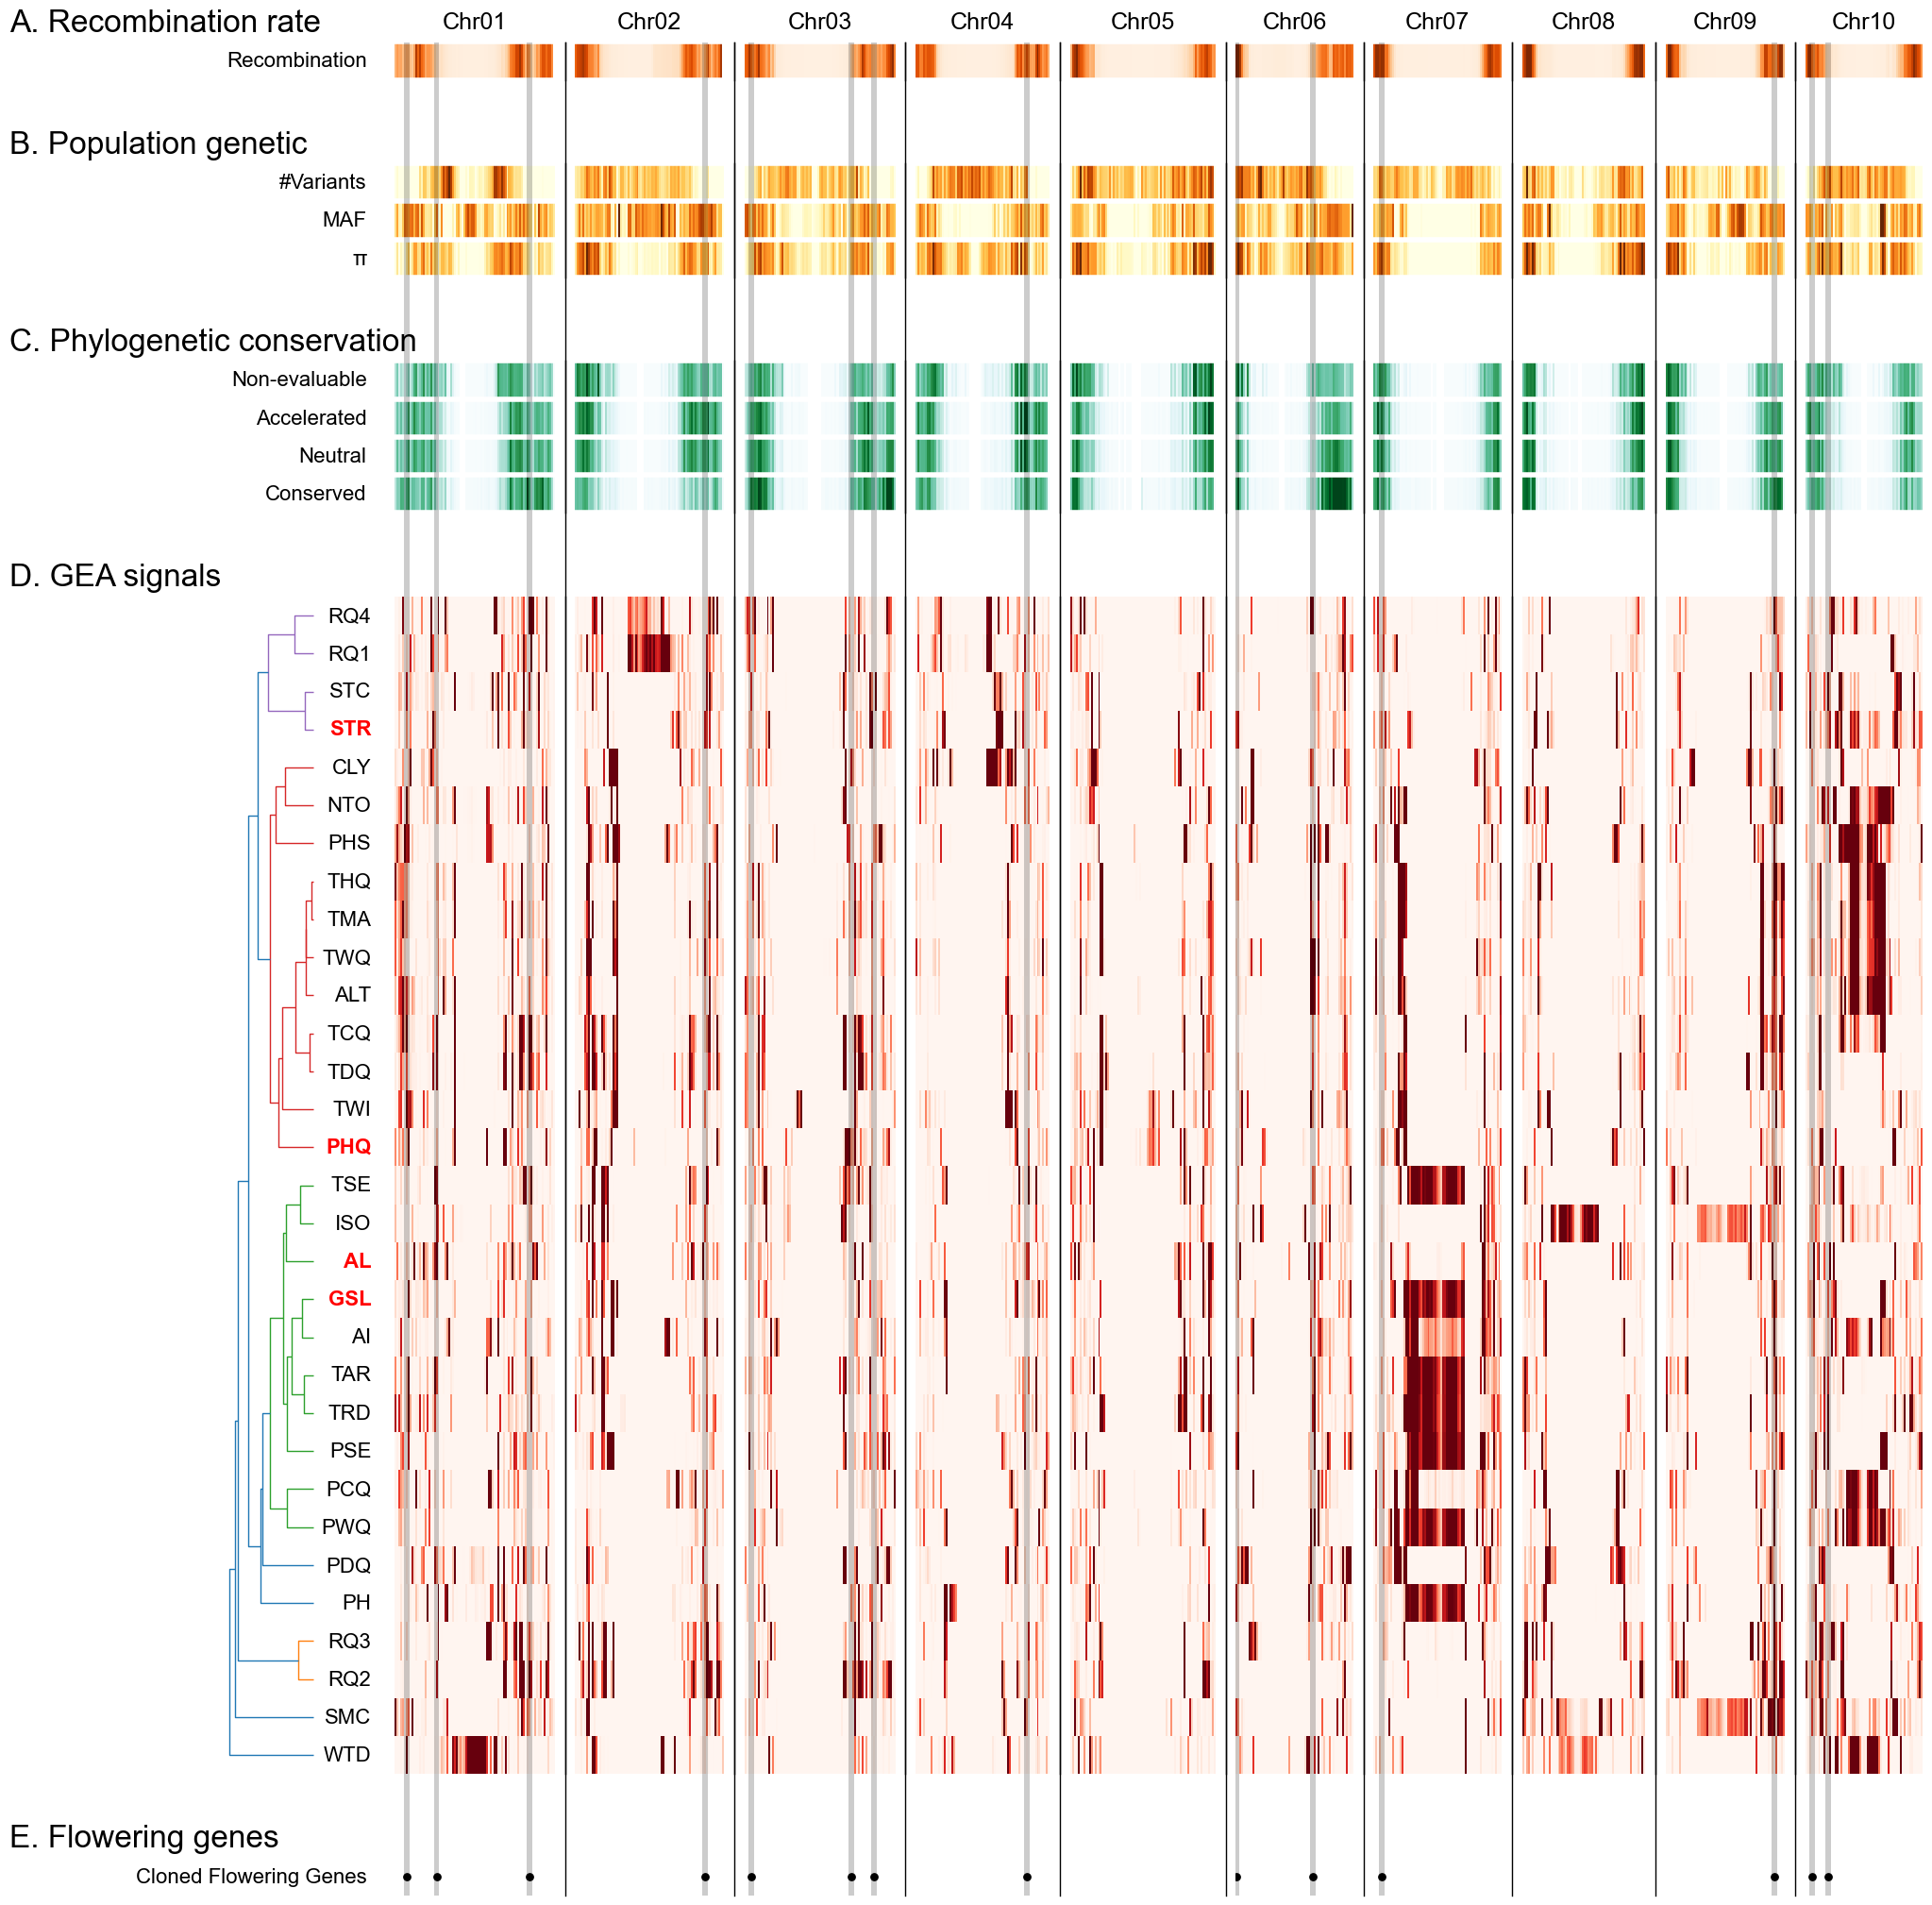

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.supp.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.supp.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/genomic_gea_landscape.supp.csv.gz'}


In [101]:
supp_landscape_plot = plot_genomic_gea_landscape(
    feature_summary_csv, gea_enrichment_csv, cloned_bins_csv,
    environment_metadata_csv, correlation_csv, f'{landscape_prefix}.supp',
    panel='supp', window_size=window_size, figsize=figsize,
    label_fontsize=label_fontsize, title_fontsize=title_fontsize,
    hspace=hspace, wspace=wspace, highlight_env_ids=key_environment_ids,
)
plt.show()
print(supp_landscape_plot['files'])


**图 15. 其他基因组特征与 GEA 信号的全基因组分布。** 染色体、窗口划分及特征轨道的 Z-score 颜色设置同图 14。（A）重组率。（B）群体遗传特征：全基因组范围的 SNP 和 indel 数量、平均次要等位基因频率（MAF）及核苷酸多样性（π）。平均 MAF 使用 MAF ≥0.05 的变异；多样性与重组率汇总有效 500 bp 窗口的统计量。（C）系统发育保守性类别：基因及两侧各 15 kb 内的不可评估、加速、中性和保守位点。（D）GEA 信号：每行代表一个环境变量，环境变量聚类和 −log10(P) 颜色设置同图 14。（E）黑点标记与已克隆开花基因本体重叠的窗口；灰色竖向带以这些标记为中心覆盖三个窗口，并贯穿上方轨道。特征与 GEA 轨道中的深色表示不同统计量。



## 4. 开花时间基因

通过文献整理和拟南芥开花基因同源映射，共汇总 312 个高粱开花相关基因，包括 52 个文献整理的基因和 260 个由 FLOR-ID 拟南芥开花基因同源映射得到的基因。文献整理的基因中包含 14 个高粱中已克隆的开花基因，完整列表见 `Sorghum_flowering_genes.csv`。

考察开花时间基因的环境关联、其与 cis-eQTL 信号的联系，以及编码与非编码变异。



### 4.1 基因级 GEA 富集

比较开花时间基因与四个重点环境变量中 MAGMA 关联最强的 5% 基因。通过染色体内开花时间标签循环置换，评估观测 Jaccard 指数。



In [102]:
import json
import gzip
import numpy as np
from src.enrich import gene_contrast_runner

contrast_id = 'flowering_time_genes'
key_environment_ids = ['bio18', 'gsl', 'al', 'striga']
with open(f'{project_dir}/config/contrasts_settings.json') as handle:
    contrast = json.load(handle)[contrast_id]
enrichment_environment_ids = key_environment_ids
permutations = 1000
top_percent = 0.05
enrichment_dir = f'{results_dir}/enrichment/flowering_time_genes'
os.makedirs(enrichment_dir, exist_ok=True)
enrichment_result_file = f'{enrichment_dir}/{contrast_id}.enrichment.json.gz'
figure_prefix = f'{enrichment_dir}/{contrast_id}'


In [103]:
stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Preparing flowering-time gene associations')
gene_associations_df = pd.read_hdf(f'{results_dir}/gene_contexts.h5', key='df')
if not gene_associations_df['ID'].is_unique:
    raise ValueError('Gene IDs must be unique for association alignment.')
for env_id in enrichment_environment_ids:
    gene_gwas_file = f'{results_dir}/gwas/{env_id}/{env_id}.magma/{env_id}.magma.gwas_df.h5'
    gene_gwas_df = pd.read_hdf(gene_gwas_file, key='df')[['ID', 'P_VALUE']]
    gene_gwas_df[env_id] = -np.log10(gene_gwas_df['P_VALUE'])
    gene_associations_df = gene_associations_df.merge(
        gene_gwas_df[['ID', env_id]], on='ID', how='left', validate='one_to_one',
    )
enrichment_result_file = gene_contrast_runner(
    contrast_id, contrast, gene_associations_df, enrichment_environment_ids,
    enrichment_dir, permutations=permutations, top_percent=top_percent,
)
print(f'[{datetime.now():%H:%M:%S}] Gene-level enrichment ready ({perf_counter() - stage_start:.1f}s)')
print(f'Results: {enrichment_result_file}')


[00:42:10] Preparing flowering-time gene associations
Enrichment results already exist for contrast flowering_time_genes, skipping.
[00:42:11] Gene-level enrichment ready (0.9s)
Results: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/flowering_time_genes/flowering_time_genes.enrichment.json.gz


- 展示开花时间基因富集



Figure and data: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/flowering_time_genes/flowering_time_genes.{pdf,png,csv.gz,histogram.csv.gz}


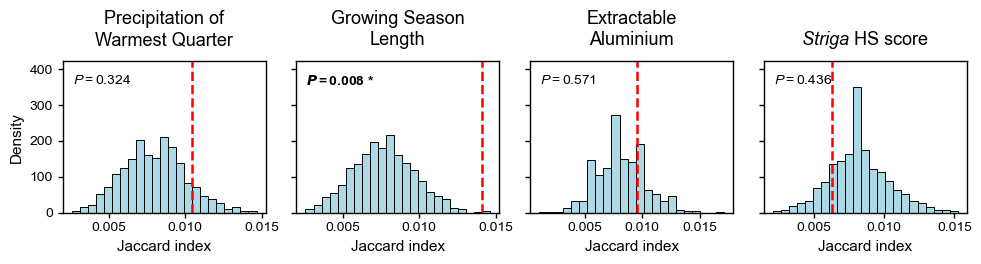

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/flowering_time_genes/flowering_time_genes.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/flowering_time_genes/flowering_time_genes.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/flowering_time_genes/flowering_time_genes.csv.gz', 'histogram_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/flowering_time_genes/flowering_time_genes.histogram.csv.gz'}


In [109]:
import matplotlib.pyplot as plt
from src.enrich import plot_gene_enrichment_histogram

environment_metadata_df = pd.read_csv(f'{source_dir}/envir_metadata.csv')
histogram_bins = 23
enrichment_plot = plot_gene_enrichment_histogram(
    enrichment_result_file, enrichment_environment_ids, environment_metadata_df,
    output_prefix=figure_prefix, figsize=(10, 2.8), bins=histogram_bins,
)
fig, axes = enrichment_plot['figure'], enrichment_plot['axes']
plot_df = enrichment_plot['plot_data']
plt.show()
print(enrichment_plot['files'])


**图 16. 开花时间基因在 GEA 关联最强的 5% 候选基因中的富集。** 对每个环境变量，红色虚线表示开花时间基因与 MAGMA 确定的 GEA 关联最强的 5% 候选基因之间的观测 Jaccard 指数。浅蓝色直方图展示对开花基因标签进行 1,000 次染色体内循环置换得到的零分布。各面板对应四个重点环境变量，并标注双侧经验 P 值。



### 4.2 个别开花时间基因的 GEA 与表达关联

结合环境关联和前期表达 GWAS（expGWAS）结果，考察个别开花时间基因区域。



#### 4.2.1 cis-eQTL 结果

前期 expGWAS 使用 318 个表达样本，采用纳入亲缘矩阵的 GEMMA 模型。SNP 和 indel 通过 MAF ≥0.05、杂合率 ≤0.05 和缺失率 ≤0.5 的过滤；保留超过 20% 样本中 TPM >1 的基因。表达量经 log2(TPM + 1) 和逆正态转换，在基因及两侧各 15 kb 范围内进行 cis 检验，每个基因开展 100 次表型置换。



- 估计 cis-eQTL 的经验 FDR

使用各基因 cis 区域的真实和置换最小 P 值，估计基因水平经验 FDR。以置换与真实最小 P 值的累积比例之比构建曲线，通过插值确定 FDR =0.05 对应的 nominal P 阈值。



In [110]:
from src.eqtl import (
    prepare_cis_eqtl_fdr, plot_cis_eqtl_fdr, prepare_cis_eqtl_egenes,
    prepare_flowering_gene_loci, plot_flowering_gene_locus,
)

cis_eqtl_dir = f'{results_dir}/cis_eQTL'
permutation_pval_csv = f'{source_dir}/eQTL_perm_pval.csv.gz'
cis_eqtl_site_csv = f'{source_dir}/cis_eQTL_all_genes_sites.csv.gz'
tpm_csv = f'{source_dir}/RNAseqPanel.tpm.csv.gz'
fdr_curve_csv = f'{cis_eqtl_dir}/cis_eQTL.fdr.csv.gz'
cis_eqtl_threshold_csv = f'{cis_eqtl_dir}/cis_eQTL.threshold.csv.gz'
fdr_threshold = 0.05
force_recompute = False


In [111]:
fdr_result = prepare_cis_eqtl_fdr(
    permutation_pval_csv, cis_eqtl_dir, fdr_threshold=fdr_threshold,
    force_recompute=force_recompute,
)
print(f"Observed minima: {int(fdr_result['summary'].iloc[0]['N_OBS']):,}")
print(f"Permuted minima: {int(fdr_result['summary'].iloc[0]['N_PERM']):,}")
print(f"P threshold: {fdr_result['pvalue_threshold']:.16g}")
fdr_result['summary']


[00:47:47] Reusing empirical FDR: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/cis_eQTL.fdr.csv.gz
Observed minima: 18,854
Permuted minima: 1,885,400
P threshold: 0.0008624278152523001


,FDR_THRESHOLD,P_VALUE_THRESHOLD,N_OBS,N_PERM,PERMUTATIONS_PER_GENE
0,0.05,0.000862,18854,1885400,100.0


展示经验 FDR 曲线



[00:47:56] Plotting empirical cis-eQTL FDR


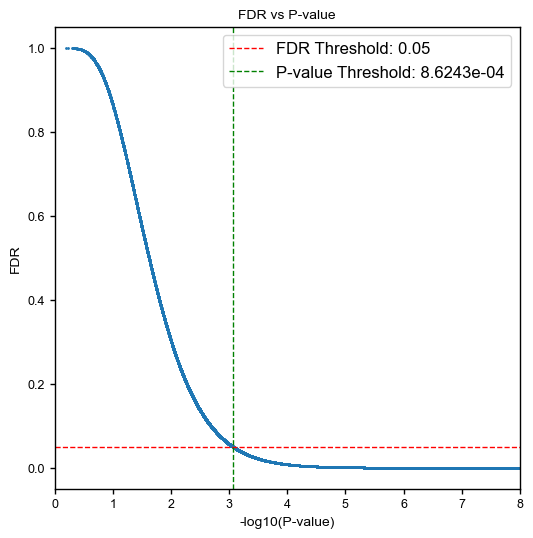

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/cis_eQTL.empirical_fdr.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/cis_eQTL.empirical_fdr.png', 'data': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/cis_eQTL.empirical_fdr.csv.gz'}


In [112]:
import matplotlib.pyplot as plt

fdr_plot = plot_cis_eqtl_fdr(
    fdr_curve_csv, cis_eqtl_threshold_csv, f'{cis_eqtl_dir}/cis_eQTL.empirical_fdr',
    figsize=(6, 6),
)
plt.show()
print(fdr_plot['files'])


**图 17. cis-eQTL 的基因水平经验 FDR。** 曲线基于各基因 cis 区域的真实和置换最小 P 值。红线标记 FDR =0.05，绿线标记对应的 nominal P 阈值。



- 识别 eGenes

将至少一个 cis 位点的 nominal P 值严格低于经验阈值的基因定义为 eGene。



In [44]:
egene_result = prepare_cis_eqtl_egenes(
    cis_eqtl_site_csv, cis_eqtl_threshold_csv, cis_eqtl_dir,
    force_recompute=force_recompute,
)
egene_ids = egene_result['gene_ids']
egene_list = egene_result['files']['gene_list']
print(f'eGenes: {len(egene_ids):,};')
print(f'eGene list: {egene_list}')
egene_result['summary'].head()


[22:18:24] Reusing 12,454 eGenes
eGenes: 12,454;
eGene list: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/cis_eQTL_gene_id_list.txt


,GENE,N_TESTED,N_SIGNIFICANT,LEAD_ID,CHROM,LEAD_POS,MIN_P,P_VALUE_THRESHOLD
0,Sobic.001G000300.v5.1,188,15,SNP_Chr01_39503,Chr01,39503,4.323326e-08,0.000862
1,Sobic.001G000400.v5.1,314,24,SNP_Chr01_50639,Chr01,50639,2.760949e-04,0.000862
2,Sobic.001G000700.v5.1,173,91,SNP_Chr01_66594,Chr01,66594,5.089408e-32,0.000862
3,Sobic.001G000800.v5.1,191,27,SNP_Chr01_92806,Chr01,92806,3.358361e-04,0.000862
4,Sobic.001G001300.v5.1,214,88,INDEL_Chr01_135901,Chr01,135901,2.731979e-15,0.000862


#### 4.2.2 个别开花时间基因区域



- 准备区域关联及基因型分组

对每个基因，在通过经验 cis-eQTL P 阈值的共享位点中选择环境关联最强的位点。使用同一标记，按纯合基因型对环境测量值和原始 TPM 分组。



In [45]:
locus_output_dir = f'{results_dir}/flowering_time_genes'
all_samples_vcf_file = f'{results_dir}/Sorghum_d8.allChr.imputed_snpeff.vcf.gz'
gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
landrace_metadata_csv = f'{source_dir}/landraces_metadata.csv'
environment_metadata_csv = f'{source_dir}/envir_metadata.csv'
gwas_dir = f'{results_dir}/gwas'
gene_plot_configs = [
    dict(gene_id='Sobic.009G257300.v5.1', gene_name='ELF3', env_id='gsl',
         marker_index=0, marker_id=None, flank_size=18000),
    dict(gene_id='Sobic.004G161701.v5.1', gene_name='LWD1', env_id='gsl',
         marker_index=0, marker_id=None, flank_size=18000),
]


In [46]:
locus_summary = prepare_flowering_gene_loci(
    gene_plot_configs, cis_eqtl_site_csv, tpm_csv, cis_eqtl_threshold_csv,
    all_samples_vcf_file, gff_file, landrace_metadata_csv,
    environment_metadata_csv, gwas_dir, locus_output_dir,
    force_recompute=force_recompute,
)
locus_summary


[22:18:25] Reusing prepared flowering-gene loci


,GENE,GENE_NAME,ENV_ID,ENV_NAME,ENV_UNITS,CHROM,START,END,FLANK_SIZE,MARKER_ID,...,TOP1_P,TOP5_P,EQTL_THRESHOLD,N_CIS_TESTED,N_ENV_REF,N_ENV_ALT,N_EXPR_REF,N_EXPR_ALT,LOCUS_FILE,SUMMARY_FILE
0,Sobic.009G257300.v5.1,ELF3,gsl,Grow.Season.Len,days,Chr09,62951808,62992860,18000,SNP_Chr09_62969740,...,0.007575,0.050508,0.000862,158,198,237,218,96,/lustre/home/dobby/Work/Project/functional-gen...,/lustre/home/dobby/Work/Project/functional-gen...
1,Sobic.004G161701.v5.1,LWD1,gsl,Grow.Season.Len,days,Chr04,53482206,53521352,18000,SNP_Chr04_53506205,...,0.007575,0.050508,0.000862,111,183,250,186,120,/lustre/home/dobby/Work/Project/functional-gen...,/lustre/home/dobby/Work/Project/functional-gen...


展示个别开花时间基因区域



[22:18:25] Plotting flowering-gene locus: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.009G257300.v5.1.gsl.locus.csv.gz


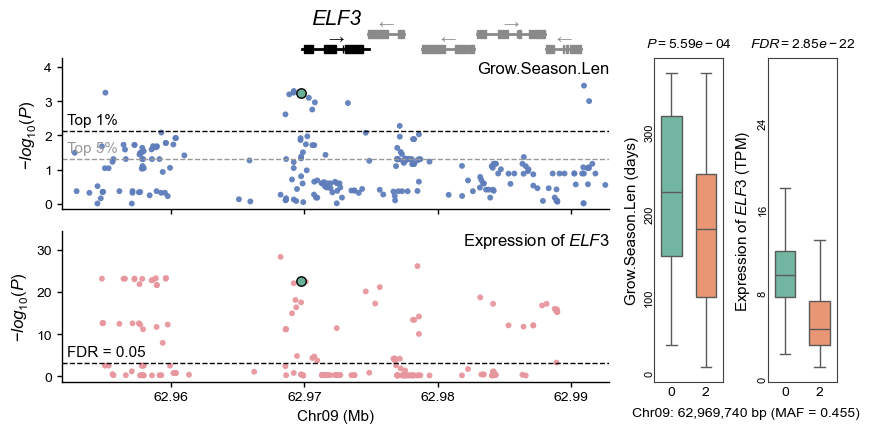

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.009G257300.v5.1.gsl.compact.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.009G257300.v5.1.gsl.compact.png', 'data': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.009G257300.v5.1.gsl.compact.csv.gz'}


In [47]:
plot_params = dict(
    figsize=(10, 4.2), title_fontsize=15, panel_label_fontsize=11,
    y_label_fontsize=12, tick_fontsize=10, step_mb=0.01,
)
elf3_config = gene_plot_configs[0]
elf3_prefix = f"{locus_output_dir}/{elf3_config['gene_id']}.{elf3_config['env_id']}"
elf3_locus_plot = plot_flowering_gene_locus(
    f'{elf3_prefix}.locus.csv.gz', f'{elf3_prefix}.summary.csv.gz',
    f'{elf3_prefix}.compact', **plot_params,
)
plt.show()
print(elf3_locus_plot['files'])


**图 18. 开花时间基因 `ELF3` 的局部关联图。** 基因结构展示在关联图上方，黑色表示目标基因，灰色表示邻近基因；基因组坐标以 Mb 为单位。上方蓝色散点图展示变异基因型与生长季长度的关联，浅色和深色虚线分别表示全基因组 envGWAS 最强 5% 和 1% 关联的 P 值阈值。下方粉色散点图展示变异基因型与目标基因表达量的关联（cis-eQTL），虚线表示经验 FDR =0.05 对应的 nominal P 值阈值。绿色散点标记共享位点。箱线图展示该位点纯合基因型（0 和 2）对应的生长季长度及原始基因表达 TPM，标题报告标记位点的 GEA P 值和基因内 cis-eQTL 的 BH FDR。展示区域包括两侧各 18 kb，cis-eQTL 检验覆盖两侧各 15 kb。



[22:18:26] Plotting flowering-gene locus: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.004G161701.v5.1.gsl.locus.csv.gz


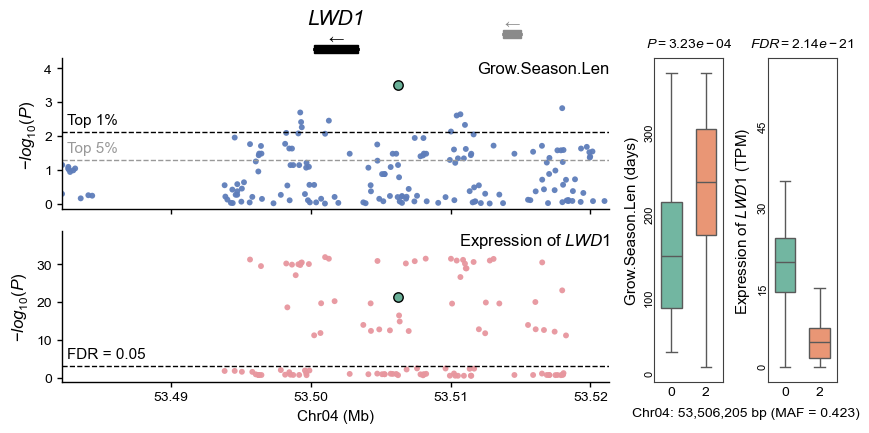

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.004G161701.v5.1.gsl.compact.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.004G161701.v5.1.gsl.compact.png', 'data': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/flowering_time_genes/Sobic.004G161701.v5.1.gsl.compact.csv.gz'}


In [48]:
lwd1_config = gene_plot_configs[1]
lwd1_prefix = f"{locus_output_dir}/{lwd1_config['gene_id']}.{lwd1_config['env_id']}"
lwd1_locus_plot = plot_flowering_gene_locus(
    f'{lwd1_prefix}.locus.csv.gz', f'{lwd1_prefix}.summary.csv.gz',
    f'{lwd1_prefix}.compact', **plot_params,
)
plt.show()
print(lwd1_locus_plot['files'])


**图 19. 开花时间基因 `LWD1` 的局部关联图。** 基因结构展示在关联图上方，黑色表示目标基因，灰色表示邻近基因；基因组坐标以 Mb 为单位。上方蓝色散点图展示变异基因型与生长季长度的关联，浅色和深色虚线分别表示全基因组 envGWAS 最强 5% 和 1% 关联的 P 值阈值。下方粉色散点图展示变异基因型与目标基因表达量的关联（cis-eQTL），虚线表示经验 FDR =0.05 对应的 nominal P 值阈值。绿色散点标记共享位点。箱线图展示该位点纯合基因型（0 和 2）对应的生长季长度及原始基因表达 TPM，标题报告标记位点的 GEA P 值和基因内 cis-eQTL 的 BH FDR。展示区域包括两侧各 18 kb，cis-eQTL 检验覆盖两侧各 15 kb。



### 4.3 调控相关 GEA 候选基因中的开花基因富集

识别 lead GEA 与 cis-eQTL 位点存在连锁的 GSL 关联基因。以完整 eGene 集合为背景，分别检验文献整理与完整开花基因集合的富集。



- 比较 lead cis-eQTL 与 GEA 位点

在各 eGene 及两侧各 15 kb 范围内，独立选择符合条件的最强 cis-eQTL 和 GSL 关联位点。在地方品种与 RNA panel 样本并集中计算等位基因剂量 r²，以 r² ≥0.25 定义调控相关 GEA 候选基因。



In [113]:
from src.eqtl import (
    prepare_regulatory_gea_genes, plot_regulatory_gea_r2,
    prepare_regulatory_gea_enrichment,
)

env_id = 'gsl'
flank_size = 15000
top_fraction = 0.05
r2_threshold = 0.25
force_recompute = False
cis_eqtl_dir = f'{results_dir}/cis_eQTL'
output_prefix = f'{cis_eqtl_dir}/reg_GEA.{env_id}.flank{flank_size}'
egene_list = f'{cis_eqtl_dir}/cis_eQTL_gene_id_list.txt'
cis_eqtl_threshold_csv = f'{cis_eqtl_dir}/cis_eQTL.threshold.csv.gz'
cis_eqtl_site_csv = f'{source_dir}/cis_eQTL_all_genes_sites.csv.gz'
tpm_csv = f'{source_dir}/RNAseqPanel.tpm.csv.gz'
landrace_metadata_csv = f'{source_dir}/landraces_metadata.csv'
all_samples_vcf_file = f'{results_dir}/Sorghum_d8.allChr.imputed_snpeff.vcf.gz'
gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
gwas_h5 = f'{results_dir}/gwas/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
pairs_csv = f'{output_prefix}.pairs.csv.gz'
comparison_summary_csv = f'{output_prefix}.summary.csv.gz'


In [114]:
lead_comparison = prepare_regulatory_gea_genes(
    egene_list, cis_eqtl_site_csv, cis_eqtl_threshold_csv, gwas_h5,
    tpm_csv, landrace_metadata_csv, all_samples_vcf_file, gff_file, output_prefix,
    env_id=env_id, flank_size=flank_size,
    top_fraction=top_fraction, r2_threshold=r2_threshold,
    force_recompute=force_recompute,
)
print(lead_comparison['pairs']['STATUS'].value_counts())
print(f"Candidate gene list: {lead_comparison['files']['gene_list']}")
lead_comparison['summary']


[01:12:49] Reusing regulatory GEA candidates: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/reg_GEA.gsl.flank15000
STATUS
compared              10595
no_top_gea_variant     1859
Name: count, dtype: int64
Candidate gene list: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/reg_GEA.gsl.flank15000.gene_ids.txt


,ENV_ID,N_EGENES,N_LEAD_PAIRS,N_VALID_CORRELATIONS,N_REG_GEA,N_RNA_SAMPLES,N_LANDRACE_SAMPLES,N_UNION_SAMPLES,FLANK_SIZE,TOP_FRACTION,GEA_P_THRESHOLD,EQTL_P_THRESHOLD,R2_THRESHOLD
0,gsl,12454,10595,10595,2005,318,443,757,15000,0.05,0.050508,0.000862,0.25


展示 lead 位点间的连锁关系



[22:18:28] Plotting lead-variant genotype correlations


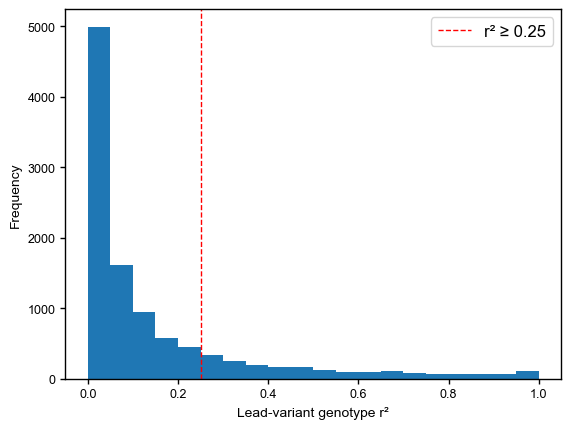

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/reg_GEA.gsl.flank15000.r2.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/reg_GEA.gsl.flank15000.r2.png', 'data': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/reg_GEA.gsl.flank15000.r2.csv.gz', 'histogram': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/cis_eQTL/reg_GEA.gsl.flank15000.r2.histogram.csv.gz'}


In [51]:
import matplotlib.pyplot as plt

histogram_bins = 20
r2_plot = plot_regulatory_gea_r2(
    pairs_csv, comparison_summary_csv, f'{output_prefix}.r2',
    bins=histogram_bins, figsize=(6.4, 4.8),
)
plt.show()
print(r2_plot['files'])


**图 20. 生长季长度关联位点与 cis-eQTL 的基因型相关性。** 直方图展示 eGenes 中生长季长度关联的 lead 位点与 lead cis-eQTL 位点之间的基因型相关性（r²）分布，虚线标记用于筛选调控相关 GEA 候选基因的阈值 r² =0.25。



- 检验文献整理的开花基因富集

使用单侧超几何检验和 Fisher 精确检验，评估与调控相关 GEA 候选基因的重叠。文献整理的开花基因集合与完整 eGene 背景取交集，背景保留没有符合条件的局部 GEA 位点的 eGenes。



In [52]:
flowering_csv = f'{source_dir}/Sorghum_flowering_genes.csv'
annotation_source = 'Literature-curated genes'
enrichment_prefix = f'{output_prefix}.flowering_time_genes.curated'
curated_enrichment = prepare_regulatory_gea_enrichment(
    f'{output_prefix}.background.csv.gz', f'{output_prefix}.candidates.csv.gz',
    flowering_csv, enrichment_prefix,
    annotation_source=annotation_source,
    force_recompute=force_recompute,
)
curated_enrichment['summary']


[22:18:29] Reusing flowering-gene regulatory GEA enrichment


,BACKGROUND,ANNOTATION_SOURCE,N_BACKGROUND,N_FLOWERING,N_REG_GEA,N_OVERLAP,EXPECTED_OVERLAP,FOLD_ENRICHMENT,ODDS_RATIO,HYPERGEOM_P,FISHER_GREATER_P
0,eGenes,Literature-curated genes,12454,25,2005,10,4.024811,2.484589,3.486717,0.003629,0.003629


In [53]:
curated_enrichment['contingency']


,FLOWERING_CLASS,REG_GEA,NOT_REG_GEA
0,Literature-curated genes,10,15
1,Other eGenes,1995,10434


- 检验全部开花基因的富集

对包含同源预测注释的完整开花基因集合进行相同检验，沿用相同的 eGene 背景和调控相关 GEA 候选集合。



In [54]:
enrichment_prefix = f'{output_prefix}.flowering_time_genes.all'
flowering_enrichment = prepare_regulatory_gea_enrichment(
    f'{output_prefix}.background.csv.gz', f'{output_prefix}.candidates.csv.gz',
    flowering_csv, enrichment_prefix,
    force_recompute=force_recompute,
)
flowering_enrichment['summary']


[22:18:30] Reusing flowering-gene regulatory GEA enrichment


,BACKGROUND,ANNOTATION_SOURCE,N_BACKGROUND,N_FLOWERING,N_REG_GEA,N_OVERLAP,EXPECTED_OVERLAP,FOLD_ENRICHMENT,ODDS_RATIO,HYPERGEOM_P,FISHER_GREATER_P
0,eGenes,All flowering genes,12454,139,2005,22,22.377951,0.983111,0.979712,0.570942,0.570942


In [55]:
flowering_enrichment['contingency']


,FLOWERING_CLASS,REG_GEA,NOT_REG_GEA
0,All flowering genes,22,117
1,Other eGenes,1983,10332


### 4.4 开花时间基因中非编码与编码区的 GEA 信号比较

比较开花基因及两侧各 2 kb 范围内非 CDS 与 CDS 变异的环境关联强度。使用同一套 MAF ≥0.05 的全基因组变异，分别分析文献整理与完整基因集合。



- 比较关联强度

以非 CDS 变异 −log10(P) 的第 95 百分位数除以 CDS 变异的对应值。通过染色体内标签循环置换进行双侧经验检验，分析四个重点环境变量及 MAF 分层。



In [56]:
import json
import gzip
import pickle
import numpy as np
from tqdm.auto import tqdm
from src.enrich import site_contrast_runner, filter_df_by_set_expr, plot_enrichment_and_overlap
from src.ld import calculate_ld_matrix, calculate_contrast_ld_overlap

contrasts_json = f'{project_dir}/config/contrasts_settings.json'
with open(contrasts_json) as handle:
    contrasts_settings = json.load(handle)
contrast_ids = ['core_flowering_non_coding_vs_coding', 'flowering_non_coding_vs_coding']
site_contexts_h5 = f'{results_dir}/site_contexts.genome.maf0.05.h5'
gwas_dir = f'{results_dir}/gwas'
landraces_qc_vcf_file = f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz'
enrichment_environment_ids = list(key_environment_ids)
permutations = 1000
top_percent = 0.05
pool_num = project_config['resources']['interactive']['cores']
ld_window_size = 15000
min_r2 = 0.5
bin_width = 0.05
random_seed = 42
enrichment_dir = f'{results_dir}/enrichment/flowering_time_genes/non_coding_vs_coding'
os.makedirs(enrichment_dir, exist_ok=True)
ld_pairs_h5 = f'{enrichment_dir}/flowering_sites.ld{ld_window_size}.r2{min_r2}.h5'
ld_overlap_dir = f'{enrichment_dir}/ld_overlap.{".".join(enrichment_environment_ids)}'
os.makedirs(ld_overlap_dir, exist_ok=True)


In [57]:
stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Preparing flowering-site association scores')

stratify_columns = [s for s in contrasts_settings[contrast_ids[0]]['maf_stratify'] if s != 'all']
context_columns = ['ID', 'CHROM', 'POS', 'genic_2kb', 'CDS',
                   'core_flowering_time_genes', 'flowering_time_genes'] + stratify_columns
context_df = pd.read_hdf(site_contexts_h5, key='df')[context_columns].copy()
selected = np.zeros(len(context_df), dtype=bool)
for contrast_id in contrast_ids:
    contrast = contrasts_settings[contrast_id]
    selected |= (filter_df_by_set_expr(context_df, contrast['foreground'])
                 | filter_df_by_set_expr(context_df, contrast['background']))
context_df = context_df.loc[selected].copy()
for env_id in tqdm(enrichment_environment_ids, desc='Environmental association scores'):
    gwas_h5 = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df.h5'
    associations_df = pd.read_hdf(gwas_h5, key='df')[['ID', 'P_WALD']]
    associations_df[env_id] = -np.log10(associations_df['P_WALD'])
    context_df = context_df.merge(associations_df[['ID', env_id]], on='ID',
                                  how='left', validate='one_to_one')
context_df = context_df.set_index('ID', drop=False)
print(f'[{datetime.now():%H:%M:%S}] Prepared {len(context_df):,} sites in {perf_counter() - stage_start:.1f}s')
context_df.head()


[22:18:31] Preparing flowering-site association scores


Environmental association scores: 100%|██████████| 4/4 [01:04<00:00, 16.11s/it]

[22:19:40] Prepared 25,643 sites in 68.9s


,ID,CHROM,POS,genic_2kb,CDS,core_flowering_time_genes,flowering_time_genes,maf_0.05_0.1,maf_0.1_0.2,maf_0.2_0.3,maf_0.3_0.4,maf_0.4_0.5,bio18,gsl,al,striga
ID,,,,,,,,,,,,,,,,
SNP_Chr01_471992,SNP_Chr01_471992,Chr01,471992,True,False,False,True,False,True,False,False,False,1.140521,2.717776,1.326548,0.072920
SNP_Chr01_472103,SNP_Chr01_472103,Chr01,472103,True,False,False,True,False,False,False,True,False,1.080216,0.140536,0.227494,0.089201
SNP_Chr01_472674,SNP_Chr01_472674,Chr01,472674,True,False,False,True,False,False,False,True,False,0.832441,0.411710,0.429583,0.243979
SNP_Chr01_472694,SNP_Chr01_472694,Chr01,472694,True,False,False,True,False,True,False,False,False,0.669106,0.349658,0.086765,0.087372
INDEL_Chr01_472923,INDEL_Chr01_472923,Chr01,472923,True,False,False,True,True,False,False,False,False,1.237393,0.718372,0.123139,0.439765


- 评估两组位点间的连锁联系

在 15 kb 内以 r² >0.5 评估非 CDS 与 CDS 变异间的 LD。比较对应的 5% 宽度关联排名区间，以两组平均最大缩放 r² 的调和平均值作为连锁指标，并以打乱关联分数作为参照。



In [58]:
print(f'[{datetime.now():%H:%M:%S}] Preparing LD pairs')
if os.path.exists(ld_pairs_h5):
    ld_df = pd.read_hdf(ld_pairs_h5, key='df')
else:
    ld_df = calculate_ld_matrix(
        context_df, landraces_qc_vcf_file, ld_window_size=ld_window_size,
        min_r2=min_r2, pool_num=pool_num,
    )
    temporary_h5 = f'{ld_pairs_h5}.tmp'
    ld_df.to_hdf(temporary_h5, key='df', mode='w')
    os.replace(temporary_h5, ld_pairs_h5)
print(f'[{datetime.now():%H:%M:%S}] Retained {len(ld_df):,} LD pairs')
ld_df.head()


[22:19:40] Preparing LD pairs
[22:19:40] Retained 617,086 LD pairs


,INDEX_1,INDEX_2,R2
0,SNP_Chr01_8345872,SNP_Chr01_8346947,0.960754
1,SNP_Chr01_8345872,SNP_Chr01_8354116,0.808145
2,SNP_Chr01_8345872,SNP_Chr01_8354193,0.952187
3,SNP_Chr01_8346074,INDEL_Chr01_8354558,0.580129
4,SNP_Chr01_8346947,SNP_Chr01_8354116,0.828069


- 文献整理的开花基因



In [59]:
contrast_id = 'core_flowering_non_coding_vs_coding'
contrast = contrasts_settings[contrast_id]
results_json_file = site_contrast_runner(
    contrast_id, contrast, context_df, enrichment_environment_ids, enrichment_dir,
    permutations=permutations, top_percent=top_percent, pool_num=pool_num,
)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(
    contrast_id, contrast, context_df, enrichment_environment_ids, ld_df, ld_overlap_dir,
    bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
)


Enrichment results already exist for contrast core_flowering_non_coding_vs_coding, skipping.
LD overlap results already exist for contrast core_flowering_non_coding_vs_coding. Skipping calculation.


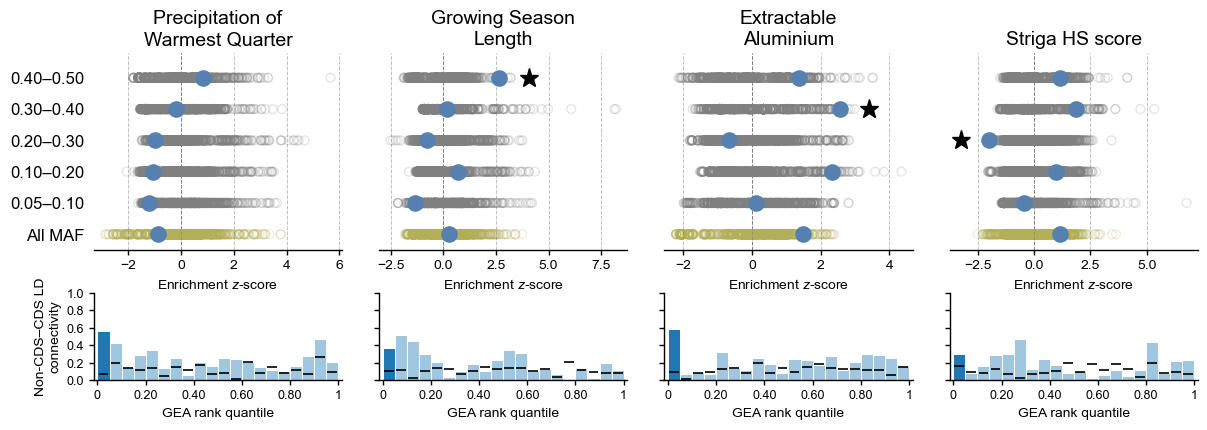

In [60]:
with gzip.open(results_json_file, 'rt') as handle:
    results_json = json.load(handle)
with open(ld_overlap_pkl_file, 'rb') as handle:
    ld_overlap_dict = pickle.load(handle)

environment_metadata_csv = f'{source_dir}/envir_metadata.csv'
environment_metadata_df = pd.read_csv(environment_metadata_csv)
stratify_label_map = [
    ['all', 'All MAF'], ['maf_0.05_0.1', '0.05–0.10'],
    ['maf_0.1_0.2', '0.10–0.20'], ['maf_0.2_0.3', '0.20–0.30'],
    ['maf_0.3_0.4', '0.30–0.40'], ['maf_0.4_0.5', '0.40–0.50'],
]
figure_prefix = f'{enrichment_dir}/{contrast_id}.enrichment_and_overlap'
fig, axes = plot_enrichment_and_overlap(
    results_json, ld_overlap_dict, enrichment_environment_ids,
    environment_metadata_df, stratify_label_map,
    bottom_ylabel='Non-CDS–CDS LD\nconnectivity', bottom_ylim=(0, 1),
    bottom_yticks=(0, 0.2, 0.4, 0.6, 0.8, 1), show=False, apply_style=False,
)
fig.savefig(f'{figure_prefix}.pdf', bbox_inches='tight')
fig.savefig(f'{figure_prefix}.png', dpi=300, bbox_inches='tight')
plt.show()

from scipy.stats import zscore

plot_frames = []
for stratum, label in stratify_label_map:
    for env_id in enrichment_environment_ids:
        result = results_json[stratum]
        values = [result['obs_values'][env_id]] + result['perm_values'][env_id]
        plot_frames.append(pd.DataFrame({
            'STRATUM': stratum, 'ENV_ID': env_id,
            'POINT_TYPE': ['observed'] + ['permutation'] * (len(values) - 1),
            'PERMUTATION_ID': [-1] + list(range(len(values) - 1)),
            'SCORE_RATIO': values, 'Z_SCORE': zscore(values),
            'P_VALUE': result['stat'][env_id]['pval'],
        }))
plot_data = pd.concat(plot_frames, ignore_index=True)
plot_data.to_csv(f'{figure_prefix}.enrichment.csv.gz', index=False, compression='gzip')
ld_plot_data = pd.concat([
    ld_overlap_dict[env_id][kind].assign(ENV_ID=env_id, POINT_TYPE=kind)
    for env_id in enrichment_environment_ids
    for kind in ['overlap_df', 'random_overlap_df']
], ignore_index=True)
ld_plot_data.to_csv(f'{figure_prefix}.ld_overlap.csv.gz', index=False, compression='gzip')


**图 21. 文献整理的开花时间基因中的非编码与编码 GEA 信号比较。** 上方面板展示四个重点环境变量中不同 MAF 分层下非 CDS 变异相对于 CDS 变异的 GEA 信号富集。观测富集值（蓝色）与 1,000 次染色体内循环标签置换得到的零分布均以 Z-score 展示；置换值以灰色表示，All MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。原始非 CDS/CDS 比值比较 −log10(P) 的第 95 百分位数，比值大于 1 表示非 CDS 信号更强。下方面板展示非 CDS 与 CDS 变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景（非 CDS）与背景（CDS）中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。



- 全部开花基因



In [61]:
contrast_id = 'flowering_non_coding_vs_coding'
contrast = contrasts_settings[contrast_id]
results_json_file = site_contrast_runner(
    contrast_id, contrast, context_df, enrichment_environment_ids, enrichment_dir,
    permutations=permutations, top_percent=top_percent, pool_num=pool_num,
)
ld_overlap_pkl_file = calculate_contrast_ld_overlap(
    contrast_id, contrast, context_df, enrichment_environment_ids, ld_df, ld_overlap_dir,
    bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
)


Enrichment results already exist for contrast flowering_non_coding_vs_coding, skipping.
LD overlap results already exist for contrast flowering_non_coding_vs_coding. Skipping calculation.


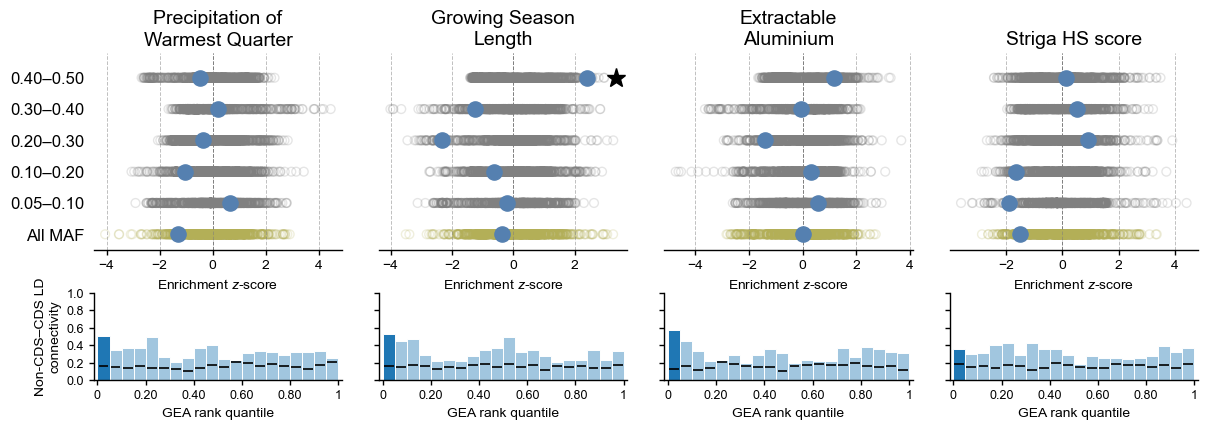

In [62]:
with gzip.open(results_json_file, 'rt') as handle:
    results_json = json.load(handle)
with open(ld_overlap_pkl_file, 'rb') as handle:
    ld_overlap_dict = pickle.load(handle)

environment_metadata_csv = f'{source_dir}/envir_metadata.csv'
environment_metadata_df = pd.read_csv(environment_metadata_csv)
stratify_label_map = [
    ['all', 'All MAF'], ['maf_0.05_0.1', '0.05–0.10'],
    ['maf_0.1_0.2', '0.10–0.20'], ['maf_0.2_0.3', '0.20–0.30'],
    ['maf_0.3_0.4', '0.30–0.40'], ['maf_0.4_0.5', '0.40–0.50'],
]
figure_prefix = f'{enrichment_dir}/{contrast_id}.enrichment_and_overlap'
fig, axes = plot_enrichment_and_overlap(
    results_json, ld_overlap_dict, enrichment_environment_ids,
    environment_metadata_df, stratify_label_map,
    bottom_ylabel='Non-CDS–CDS LD\nconnectivity', bottom_ylim=(0, 1),
    bottom_yticks=(0, 0.2, 0.4, 0.6, 0.8, 1), show=False, apply_style=False,
)
fig.savefig(f'{figure_prefix}.pdf', bbox_inches='tight')
fig.savefig(f'{figure_prefix}.png', dpi=300, bbox_inches='tight')
plt.show()

from scipy.stats import zscore

plot_frames = []
for stratum, label in stratify_label_map:
    for env_id in enrichment_environment_ids:
        result = results_json[stratum]
        values = [result['obs_values'][env_id]] + result['perm_values'][env_id]
        plot_frames.append(pd.DataFrame({
            'STRATUM': stratum, 'ENV_ID': env_id,
            'POINT_TYPE': ['observed'] + ['permutation'] * (len(values) - 1),
            'PERMUTATION_ID': [-1] + list(range(len(values) - 1)),
            'SCORE_RATIO': values, 'Z_SCORE': zscore(values),
            'P_VALUE': result['stat'][env_id]['pval'],
        }))
plot_data = pd.concat(plot_frames, ignore_index=True)
plot_data.to_csv(f'{figure_prefix}.enrichment.csv.gz', index=False, compression='gzip')
ld_plot_data = pd.concat([
    ld_overlap_dict[env_id][kind].assign(ENV_ID=env_id, POINT_TYPE=kind)
    for env_id in enrichment_environment_ids
    for kind in ['overlap_df', 'random_overlap_df']
], ignore_index=True)
ld_plot_data.to_csv(f'{figure_prefix}.ld_overlap.csv.gz', index=False, compression='gzip')


**图 22. 完整开花时间基因集合中的非编码与编码 GEA 信号比较。** 上方面板展示四个重点环境变量中不同 MAF 分层下非 CDS 变异相对于 CDS 变异的 GEA 信号富集。观测富集值（蓝色）与 1,000 次染色体内循环标签置换得到的零分布均以 Z-score 展示；置换值以灰色表示，All MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。原始非 CDS/CDS 比值比较 −log10(P) 的第 95 百分位数，比值大于 1 表示非 CDS 信号更强。下方面板展示非 CDS 与 CDS 变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景（非 CDS）与背景（CDS）中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。

